# 13 · Data-Centric AI: Better Data, Better Models

This is a module of Neural Networks 1002. It assumes [module 03 of Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) (training deep networks well: losses, regularisation, overfitting, how a network can memorise noisy labels) and [module 12](https://neural-networks.academy.forwardforecasting.eu/12-capstone-real-case/) (the capstone, where data quality decides whether the model can be trusted).

Most courses, including the first ten modules of this sequence, treat the **dataset as fixed** and ask how to improve the **model**. Data-centric AI turns this around: hold the model and the training recipe fixed, and spend the effort on the data (labels, coverage, duplicates, splits, monitoring). Andrew Ng popularised the name in 2021, arguing that for many practical problems the data is where the biggest and cheapest gains are. That is a claim, not a law, so in this notebook we **test it**: every statement below is backed by a number we measure, and where the data-centric route does *not* win we say so.

In this notebook you will build and measure, on a laptop CPU with fixed seeds:

1. the **cost of label noise** (accuracy against noise rate, for random and for class-dependent mistakes), and how noisy test labels distort the measurement itself;
2. **finding wrong labels** with **confident learning**, with a **loss-based** rule and with **ensemble disagreement**, compared with the `cleanlab` library;
3. a **fair contest**: a fixed model with better data against the same task with a bigger model, a tuned model or another model family (model-centric), at three noise levels including zero noise;
4. **annotation quality**: Cohen's kappa, ambiguous classes, and what better labelling guidelines buy;
5. **leakage and duplicates**: near-duplicate detection, the inflated test score it causes, group splits, and a leaking feature;
6. **learning curves** with confidence bands and a power-law extrapolation to decide between collecting data and changing the model;
7. **data valuation**: leave-one-out and Monte Carlo Shapley values on a small training set;
8. **active learning**: uncertainty, margin, diversity and hybrid sampling against random, with seed variation and labelling-budget savings;
9. **augmentation and synthetic data**, including a toy of **model collapse** when models are trained on their own output;
10. **weak supervision**: labelling functions and a small Snorkel-style label model;
11. **data validation and monitoring**: schema checks, the population stability index (PSI) and the Kolmogorov-Smirnov (KS) test on a worked drift example;
12. **documentation and versioning**: a datasheet and a content hash, and a checklist.

**Contents**

1. The thesis and our setup
2. What label noise costs
3. Finding wrong labels
4. Model-centric versus data-centric on one task
5. Annotation quality: agreement, ambiguity, guidelines
6. Leakage, duplicates and group splits
7. Learning curves: more data or a better model?
8. The value of each data point
9. Active learning
10. Augmentation, synthetic data and model collapse
11. Weak supervision
12. Validation and monitoring in production
13. Documentation and versioning
14. A checklist, key takeaways, exercises, references

| Builds on | What we reuse |
|---|---|
| [03 Training deep networks (1001)](https://neural-networks.academy.forwardforecasting.eu/03-training-deep-networks/) | cross-entropy, regularisation, overfitting, memorisation of noisy labels |
| [12 Capstone (1001)](https://neural-networks.academy.forwardforecasting.eu/12-capstone-real-case/) | judging a model on realistic data, the cost of bad inspection labels |
| [11 Uncertainty, calibration and robustness (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/11-uncertainty-calibration-and-robustness/) | predicted probabilities as a signal, conformal and shift ideas used here for monitoring |
| [12 Responsible AI (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/12-responsible-ai/) | who is represented in the data, documentation as an accountability tool |

New to scikit-learn, pandas or statistics tests? The [Python 1001 course, section on AI frameworks](https://python.academy.forwardforecasting.eu/11-ai-frameworks/) covers the tools, and its [time series section](https://python.academy.forwardforecasting.eu/12-time-series-forecasting/) covers evaluation on data that moves in time.

**Data and where the toys differ from real systems.** Almost everything uses the 8 by 8 pixel handwritten digits that ship with scikit-learn (1797 images, the UCI "Optical Recognition of Handwritten Digits" test set by Alpaydin and Kaynak, CC BY 4.0 licence, [doi:10.24432/C50P49](https://doi.org/10.24432/C50P49)), so nothing is downloaded; a few toys (model collapse, drift) are generated in the notebook. We **inject** mistakes (flipped labels, duplicates, drift) so that we know the truth and can score every method, which real projects never can; real label errors are not random, real datasets have millions of rows and the damage is rarely this clean. The methods and measurements carry over, the exact numbers do not. The notebook uses `cleanlab` (open source, Apache 2.0 licence, [github.com/cleanlab/cleanlab](https://github.com/cleanlab/cleanlab)) for one cross-check and falls back gracefully if it is not installed. Run time: about 3 minutes on four fast CPU cores (several sections run their seeds in parallel; the worker count follows `os.cpu_count()`), about 5 minutes when limited to 2 vCPUs (measured), so expect roughly 5 to 8 minutes on a free Colab CPU runtime. On Colab, `pip install cleanlab` is optional: without it the library cross-check line is simply skipped.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/13_data_centric_ai.ipynb)

**Running in Google Colab?** Choose *Runtime > Run all*. The first code cell installs only what is missing (no session restart needed). The times shown in this notebook were measured on a multi-core machine; a free Colab CPU runtime (about 2 cores) can take several times longer.

In [ ]:
# Setup: works locally and in Google Colab. Installs only the packages that are missing.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'cleanlab': 'cleanlab',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Installing:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('WARNING: the pip install failed; continuing. Details:\n' + _r.stderr[-400:])
print(f"Environment: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, time, math, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, ndimage
from scipy.optimize import curve_fit
from scipy.sparse.csgraph import connected_components
from scipy.sparse import coo_matrix
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from sklearn.datasets import load_digits
from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupShuffleSplit, cross_val_score)
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score, cohen_kappa_score, roc_auc_score
from sklearn.metrics.pairwise import pairwise_distances

try:
    from cleanlab.filter import find_label_issues
    HAVE_CLEANLAB = True
except Exception:
    HAVE_CLEANLAB = False

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()
K = 10

digits = load_digits()
X_ALL = (digits.data / 16.0).astype(float)      # pixel values scaled to [0, 1]
Y_ALL = digits.target
# one fixed split used by most sections: a 1200 image pool and a 597 image test set that is never touched
X_pool, X_test, y_pool, y_test = train_test_split(X_ALL, Y_ALL, test_size=597, stratify=Y_ALL, random_state=0)
Xtr, ytr = X_pool[:1000], y_pool[:1000]          # the training set of sections 2 to 4
print("pool:", X_pool.shape, "test:", X_test.shape, "cleanlab installed:", HAVE_CLEANLAB)

def _call(fn, a):
    warnings.filterwarnings("ignore")
    with threadpool_limits(1):
        return fn(a)
N_JOBS = int(os.environ.get("NN_THREADS") or min(4, os.cpu_count() or 1))     # 2 on a Colab CPU runtime
def pmap(fn, items, n_jobs=N_JOBS):
    # run independent seeds in parallel, one thread each (results do not depend on n_jobs)
    return Parallel(n_jobs=n_jobs)(delayed(_call)(fn, a) for a in items)

def mlp(seed=0, hidden=(64,), alpha=1e-4, iters=150):
    return MLPClassifier(hidden, alpha=alpha, max_iter=iters, learning_rate_init=3e-3, random_state=seed)
def logreg():
    return LogisticRegression(max_iter=300)

# two kinds of label mistakes, applied to a clean label vector
PAIR = {0: 6, 1: 7, 2: 7, 3: 8, 4: 9, 5: 9, 6: 0, 7: 1, 8: 3, 9: 4}     # look-alike partner of each class
def flip_sym(y, rate, seed):
    # symmetric noise: a random fraction `rate` of the labels is replaced by a random other class
    r = np.random.default_rng(seed); n = int(round(rate * len(y)))
    idx = r.choice(len(y), n, replace=False); y2 = y.copy()
    y2[idx] = (y[idx] + r.integers(1, K, n)) % K
    return y2
def flip_pair(y, rate, seed):
    # class-dependent noise: each label turns into its look-alike partner with probability `rate`
    r = np.random.default_rng(seed); y2 = y.copy(); m = r.random(len(y)) < rate
    y2[m] = np.array([PAIR[v] for v in y[m]], dtype=y.dtype)
    return y2
def noisy(y, kind, rate, seed):
    return flip_sym(y, rate, seed) if kind == "symmetric" else flip_pair(y, rate, seed)

pool: (1200, 64) test: (597, 64) cleanlab installed: True


## 1. The thesis and our setup

The **model-centric** view: the data is a given; you improve results by changing the architecture, the size, the optimiser or the hyper-parameters (the settings you choose before training, such as width or regularisation strength). The **data-centric** view: the model is good enough and fixed; you improve results by systematically improving the data: fixing wrong labels, removing duplicates, covering rare cases, writing clear labelling guidelines, splitting honestly and watching the data in production. The two are not enemies; the question is **where the next unit of effort pays more**.

The evidence for taking data seriously is partly measured and partly experience. Northcutt, Athalye and Mueller (2021) found label errors in the **test sets** of ten of the most used benchmarks, averaging 3.4 % wrong, enough to change which model looks best. Sambasivan et al. (2021) interviewed practitioners in high-stakes domains and described **data cascades**: data problems that start early, are invisible, and compound downstream, with 92 % of the teams reporting at least one. Those are findings about practice. Here we do something smaller and more checkable: run the same experiments on one small task and see which levers move the number.

Throughout, "accuracy" means accuracy on the clean test set of 597 digit images. Its binomial standard error is about $\sqrt{0.95 \cdot 0.05 / 597} \approx 0.9$ percentage points, so **differences below one point between single runs are noise**; we repeat runs over seeds (a *seed* is the number that fixes the random choices) and report means with spreads.

## 2. What label noise costs

We take the 1000 training images and corrupt a fraction $\rho$ (the Greek letter rho, the **noise rate**) of their labels, in two ways:

* **Symmetric noise**: a chosen label is replaced by a uniformly random *other* class. This is the easiest case to study and the least realistic.
* **Class-dependent (pair) noise**: a label becomes its look-alike partner (1 with 7, 3 with 8, 4 with 9, 5 with 9, 0 with 6, 2 with 7) with probability $\rho$. This mimics a human who confuses similar items, and it is **harder**, because the mistakes are systematic and a model can learn them.

We train a small neural network (a multilayer perceptron with one hidden layer of 64 units) and a logistic regression on the noisy labels and measure accuracy on the **clean** test set. We also measure accuracy against a test set corrupted in the same way, to show a second cost of noise: even a perfect model looks worse when the *test* labels are wrong.

    noise  rate  MLP clean-test  MLP noisy-test  LogReg clean-test
symmetric   0.0           0.977           0.977              0.968
symmetric   0.1           0.938           0.844              0.950
symmetric   0.2           0.909           0.730              0.936
symmetric   0.3           0.882           0.618              0.920
symmetric   0.4           0.828           0.505              0.883
symmetric   0.5           0.733           0.377              0.846
     pair   0.0           0.977           0.977              0.968
     pair   0.1           0.928           0.837              0.950
     pair   0.2           0.873           0.719              0.913
     pair   0.3           0.798           0.616              0.851
     pair   0.4           0.655           0.524              0.711
     pair   0.5           0.492           0.495              0.479


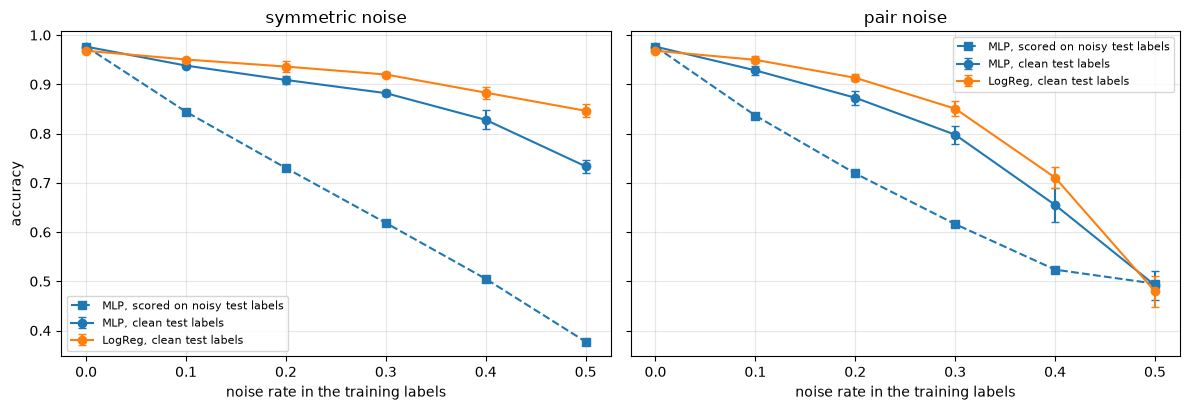

time 6 s


In [2]:
rates = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
seeds3 = [0, 1, 2, 3, 4]

def noise_task(args):
    kind, rate, s = args
    yn = noisy(ytr, kind, rate, 100 + s)
    yt_noisy = noisy(y_test, kind, rate, 200 + s)
    out = {}
    for name, m in [("MLP", mlp(s)), ("LogReg", logreg())]:
        p = m.fit(Xtr, yn).predict(X_test)
        out[name] = (accuracy_score(y_test, p), accuracy_score(yt_noisy, p))
    return out

t0 = time.time()
jobs = [(k, r, s) for k in ["symmetric", "pair"] for r in rates for s in seeds3]
res = dict(zip(jobs, pmap(noise_task, jobs)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
print(f"{'noise':>9s} {'rate':>5s} {'MLP clean-test':>15s} {'MLP noisy-test':>15s} {'LogReg clean-test':>18s}")
for a, kind in zip(ax, ["symmetric", "pair"]):
    for name, c, ls in [("MLP", "C0", "-"), ("LogReg", "C1", "-")]:
        m = np.array([[np.mean([res[(kind, r, s)][name][0] for s in seeds3]),
                       np.std([res[(kind, r, s)][name][0] for s in seeds3])] for r in rates])
        a.errorbar(rates, m[:, 0], m[:, 1], color=c, ls=ls, marker="o", capsize=3, label=f"{name}, clean test labels")
    mn = np.array([np.mean([res[(kind, r, s)]["MLP"][1] for s in seeds3]) for r in rates])
    a.plot(rates, mn, "C0--", marker="s", label="MLP, scored on noisy test labels")
    a.set_xlabel("noise rate in the training labels"); a.set_title(f"{kind} noise"); a.legend(fontsize=8)
    for r in rates:
        mm = np.mean([res[(kind, r, s)]["MLP"][0] for s in seeds3]); mt = np.mean([res[(kind, r, s)]["MLP"][1] for s in seeds3])
        ml = np.mean([res[(kind, r, s)]["LogReg"][0] for s in seeds3])
        print(f"{kind:>9s} {r:5.1f} {mm:15.3f} {mt:15.3f} {ml:18.3f}")
ax[0].set_ylabel("accuracy")
plt.tight_layout(); plt.show()
print(f"time {time.time() - t0:.0f} s")

**Reading.** Accuracy falls steadily with the noise rate, and the *structure* of the noise matters. With symmetric noise the network keeps 0.909 at 20 % noise and 0.828 at 40 % (from 0.977 with clean labels), because wrong labels are spread over nine other classes and the correct class still wins on average. With look-alike (pair) noise the same rates cost more, 0.873 at 20 % and 0.655 at 40 %, and at 50 % the model sits at 0.49: half of the 1s are labelled 7 and nothing in the data says which half. Two further observations. First, the **simpler model is more robust**: logistic regression is worse than the network on clean labels (0.968 against 0.977) but better from 10 % noise on (0.936 against 0.909 at 20 % symmetric noise, 0.913 against 0.873 at 20 % pair noise), because the network has the capacity to memorise wrong labels and logistic regression does not. Second, the dashed line shows the **cost of noisy test labels**: scored against a test set corrupted at the same rate, the same predictions look much worse (0.730 instead of 0.909 at 20 % symmetric noise, close to the clean accuracy times $1-\rho$). The gap between two models shrinks by about the same factor and gets noisier, which is how label errors in a test set can reorder a leaderboard (Northcutt, Athalye and Mueller, 2021). Error bars in the plot are one standard deviation over 5 seeds. In real data the noise is rarely uniform and rarely known; this section only fixes a scale.

## 3. Finding wrong labels

If wrong labels cost accuracy, can we **find** them? Three families of methods, all built on the same idea: *a model that has not seen an example (out-of-sample) and strongly disagrees with its label is evidence that the label is wrong*. To get out-of-sample predictions for every training example we use **5-fold cross-validation**: split the training set into five parts, train on four, predict the fifth, rotate. This gives an out-of-sample probability vector $\hat p_i$ for every example $i$ (a vector over the $K = 10$ classes).

1. **Confident learning** (Northcutt, Jiang and Chuang, 2021). For each class $j$ compute a threshold $t_j$, the average predicted probability of class $j$ over the examples *labelled* $j$ (how confident the model typically is when it is right about class $j$). An example is a **suspected error** when some *other* class $j'$ beats its own threshold, $\hat p_{i,j'} \ge t_{j'}$, and is the most probable such class, $j' \ne y_i$. Per-class thresholds matter because a model is naturally less confident about some classes than others. Our version below is the core idea (the "confident joint" of the paper, used directly as a filter); the library adds noise-rate estimation and several pruning rules.
2. **Loss-based** (the "small-loss" idea: noisy examples have large loss). Rank examples by their out-of-sample loss $-\ln \hat p_{i,y_i}$ and flag the top $k$, with $k$ set to the number confident learning flags so that the two get the same budget.
3. **Ensemble disagreement**. Four different models (logistic regression, random forest, 10-nearest-neighbours, the neural network) each vote out-of-sample; flag an example when **at least three of the four** vote for something other than its label. Diverse models make different mistakes, so agreement against the label is stronger evidence.

We score each method against the **known** truth (we injected the errors): **precision** (of those flagged, the fraction truly wrong), **recall** (of the truly wrong, the fraction flagged), their harmonic mean **F1**, and the **AUROC** (area under the ROC curve) of the method's ranking score, which does not need a threshold. Then the question that matters: **does training on the cleaned data give a better model?** We try dropping the flagged examples, relabelling them with the model's prediction, and two references: an **oracle** that drops exactly the wrong labels, and the bigger model of the model-centric view.

In [3]:
def cl_flag(P, y):
    # confident learning, core idea: per-class thresholds t_j = mean self-confidence of class j,
    # flag i when another class beats its own threshold and is the most probable such class
    t = np.array([P[y == j, j].mean() for j in range(K)])
    ok = P >= t[None, :]
    cand = np.where(ok, P, -1.0)
    best = cand.argmax(1)
    return ok.any(1) & (best != y)

def oof(make, X, y, seed, k=5):
    P = np.zeros((len(y), K))
    for a, b in StratifiedKFold(k, shuffle=True, random_state=seed).split(X, y):
        m = make().fit(X[a], y[a])
        P[np.ix_(b, m.classes_)] = m.predict_proba(X[b])
    return P

def ens_oof(X, y, seed):
    makers = {"logreg": logreg, "forest": lambda: RandomForestClassifier(100, random_state=seed, n_jobs=1),
              "knn": lambda: KNeighborsClassifier(10), "mlp": lambda: mlp(seed)}
    return {n: oof(mk, X, y, seed) for n, mk in makers.items()}
def ens_flag(ps, y):
    votes = np.stack([P.argmax(1) for P in ps.values()])
    return (votes != y[None, :]).sum(0) >= 3          # at least 3 of 4 models vote against the label

def prf(flag, truth):
    tp = (flag & truth).sum(); p = tp / max(flag.sum(), 1); r = tp / max(truth.sum(), 1)
    return p, r, 2 * p * r / max(p + r, 1e-9)

def detect_task(args):
    kind, rate, seed = args
    yn = noisy(ytr, kind, rate, 400 + seed); truth = yn != ytr; idx = np.arange(len(yn))
    ps = ens_oof(Xtr, yn, seed)
    Pm = ps["mlp"]; flags, scores = {}, {}
    flags["confident learning (ours)"] = cl_flag(Pm, yn)
    others = np.where(np.eye(K, dtype=bool)[yn], -1.0, Pm).max(1)
    scores["confident learning (ours)"] = others - Pm[idx, yn]                       # normalised margin
    loss = -np.log(np.clip(Pm[idx, yn], 1e-6, 1)); k = int(flags["confident learning (ours)"].sum())
    fl = np.zeros(len(yn), bool); fl[np.argsort(-loss)[:k]] = True
    flags["high loss (top k)"] = fl; scores["high loss (top k)"] = loss
    flags["ensemble disagreement"] = ens_flag(ps, yn)
    scores["ensemble disagreement"] = 1 - np.mean(list(ps.values()), 0)[idx, yn]
    if HAVE_CLEANLAB:
        flags["cleanlab library"] = find_label_issues(labels=yn, pred_probs=Pm, n_jobs=1)
    det = {n: (*prf(f, truth), roc_auc_score(truth, scores[n]) if n in scores else np.nan, int(f.sum())) for n, f in flags.items()}
    allk = np.ones(len(yn), bool)
    def acc(keep, lab, hidden=(64,)):
        return mlp(seed, hidden).fit(Xtr[keep], lab[keep]).score(X_test, y_test)
    g = {"no cleaning": acc(allk, yn), "bigger model (256,256), no cleaning": acc(allk, yn, (256, 256))}
    for n, f in flags.items():
        g["drop flagged: " + n] = acc(~f, yn)
    rel = yn.copy(); f = flags["confident learning (ours)"]; rel[f] = Pm[f].argmax(1)
    g["relabel flagged (confident learning)"] = acc(allk, rel)
    g["oracle: drop the true errors"] = acc(~truth, yn)
    g["clean labels (upper bound)"] = acc(allk, ytr)
    return det, g

t0 = time.time()
scen = [("symmetric", 0.2), ("pair", 0.2), ("symmetric", 0.4)]
jobs = [(k, r, s) for k, r in scen for s in range(8)]
out = dict(zip(jobs, pmap(detect_task, jobs)))
for k, r in scen:
    runs = [out[(k, r, s)] for s in range(8)]
    print(f"\n=== {k} noise {r:.0%}: detection (mean of 8 seeds; {int(round(r * 1000))} labels are wrong) ===")
    print(f"{'method':28s} {'flagged':>8s} {'precision':>10s} {'recall':>8s} {'F1':>6s} {'AUROC':>7s}")
    for n in runs[0][0]:
        v = np.array([x[0][n] for x in runs], float).mean(0)
        print(f"{n:28s} {v[4]:8.0f} {v[0]:10.2f} {v[1]:8.2f} {v[2]:6.2f} {v[3]:7.2f}")
    print(f"--- clean test accuracy of a model trained on the result (mean ± sd of 8 seeds) ---")
    for n in runs[0][1]:
        v = np.array([x[1][n] for x in runs])
        print(f"{n:42s} {v.mean():.3f} ± {v.std():.3f}")
print(f"\ntime {time.time() - t0:.0f} s")


=== symmetric noise 20%: detection (mean of 8 seeds; 200 labels are wrong) ===
method                        flagged  precision   recall     F1   AUROC
confident learning (ours)         178       0.89     0.79   0.84    0.99
high loss (top k)                 178       0.94     0.84   0.89    0.99
ensemble disagreement             223       0.89     1.00   0.94    1.00
cleanlab library                  212       0.85     0.90   0.87     nan
--- clean test accuracy of a model trained on the result (mean ± sd of 8 seeds) ---
no cleaning                                0.909 ± 0.008
bigger model (256,256), no cleaning        0.838 ± 0.012
drop flagged: confident learning (ours)    0.938 ± 0.006
drop flagged: high loss (top k)            0.944 ± 0.004
drop flagged: ensemble disagreement        0.962 ± 0.005
drop flagged: cleanlab library             0.945 ± 0.008
relabel flagged (confident learning)       0.924 ± 0.008
oracle: drop the true errors               0.972 ± 0.003
clean labels (u

**Reading.** All three detectors work well on symmetric 20 % noise (200 wrong labels among 1000): the AUROC of the ranking scores is 0.99 to 1.00, so the wrong labels are almost always among the examples the out-of-sample models disagree with. Our confident-learning filter flags 178 examples with precision 0.89 and recall 0.79; the `cleanlab` library flags 212 with precision 0.85 and recall 0.90 (it estimates the noise rate more aggressively), and the downstream accuracy of the two is the same within seed noise (0.938 against 0.945, standard deviations 0.006 to 0.008). The loss rule with the same budget is about as good (0.944). **Ensemble disagreement was the best detector in every scenario** (F1 0.94 at 20 % symmetric noise, 0.88 for pair noise, 0.96 at 40 %), but note that it uses four model families and so costs more than the single-network methods; whether the margin comes from diversity or from compute we did not separate (exercise 2 starts on it). Pair noise is harder for every method (F1 0.71 to 0.74 for the single-model methods): a systematic error looks like a legitimate pattern to a model trained on it. The gains follow the detection quality. At 20 % symmetric noise, a model trained on the ensemble-cleaned data reaches 0.962 against 0.909 without cleaning and 0.972 if an oracle removed exactly the wrong labels. The **bigger network is worse than the baseline** in every noisy scenario (0.838 against 0.909, and 0.665 against 0.826 at 40 %): extra capacity memorises more noise. **Relabelling** the flagged examples with the model's prediction was *worse* than dropping them (0.924 against 0.938, and 0.882 against 0.912 for pair noise), because the model's prediction on a flagged example is often itself wrong (the precision of the flags was only 0.7 to 0.9) and a dropped example is harmless where a wrongly relabelled one is not. All numbers are means over 8 seeds.

## 4. Model-centric versus data-centric on one task

Now the contest the introduction promised. Same task (10-class digits, 1000 noisy training labels, clean test set), same base model (the 64-unit network), and several ways to spend effort. We use symmetric noise at **three levels: 0 %, 20 % and 40 %**, because the honest question is not "does cleaning help when labels are bad" (it surely does) but "**does it hurt when labels are already good**".

Model-centric arms (the data stays as given):

* **bigger network**: two hidden layers of 256 units;
* **tuned network**: pick the width (64 or 128) and the L2 weight penalty strength `alpha` (0.0001 or 0.3) by 3-fold cross-validation **on the noisy labels** (the only labels we have, which is the realistic case);
* **another model family**: a random forest of 300 trees.

Data-centric arms (the base network stays as given):

* **clean**: confident learning from section 3, or the ensemble vote of section 3 (the better detector there), then drop the flagged examples;
* **more noisy data**: collect 200 more examples, with the same noise rate (what an extra labelling round gives you when the labelling process is unchanged);
* **clean + tune** and **forest on cleaned data**: both levers together.

The "budget" is not equal across arms (training a bigger network costs compute, cleaning costs five extra training runs, collecting costs human time), so read this as *what each lever delivers*, not as an equal-cost race.

clean test accuracy, mean ± sd of 8 seeds
                                               0% noise      20% noise      40% noise
baseline                                  0.977 ± 0.002  0.911 ± 0.007  0.824 ± 0.015
bigger network                            0.980 ± 0.002  0.843 ± 0.014  0.655 ± 0.018
tuned network                             0.979 ± 0.002  0.941 ± 0.004  0.872 ± 0.012
random forest                             0.963 ± 0.003  0.959 ± 0.006  0.927 ± 0.007
clean (confident learning)                0.975 ± 0.004  0.933 ± 0.009  0.889 ± 0.012
clean (ensemble vote)                     0.968 ± 0.003  0.961 ± 0.006  0.947 ± 0.007
+200 more noisy examples                  0.976 ± 0.001  0.915 ± 0.014  0.829 ± 0.024
clean (CL) + tune                         0.977 ± 0.002  0.949 ± 0.005  0.903 ± 0.011
random forest on cleaned (ensemble vote)  0.960 ± 0.003  0.952 ± 0.003  0.942 ± 0.007
examples removed by cleaning (mean), confident learning / ensemble vote: {'0%': (5, 22), '20%': (1

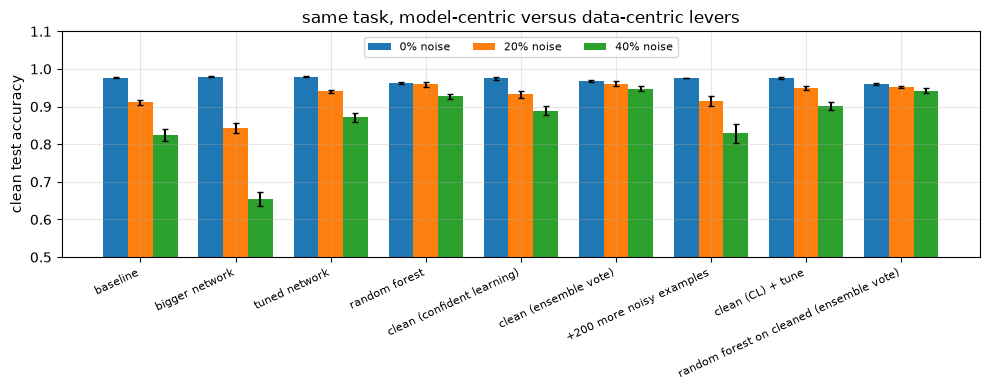

time 68 s


In [4]:
GRID = [((64,), 1e-4), ((64,), 0.3), ((128,), 1e-4), ((128,), 0.3)]
def tune(X, y, seed):
    best = max(GRID, key=lambda g: cross_val_score(mlp(seed, g[0], g[1]), X, y, cv=3).mean())
    return mlp(seed, best[0], best[1]).fit(X, y), best

def contest_task(args):
    rate, seed = args
    yn = flip_sym(ytr, rate, 500 + seed)
    Xe, ye = X_pool[1000:], flip_sym(y_pool[1000:], rate, 600 + seed)
    sc = lambda m: m.score(X_test, y_test)
    r = {}
    r["baseline"] = sc(mlp(seed).fit(Xtr, yn))
    r["bigger network"] = sc(mlp(seed, (256, 256)).fit(Xtr, yn))
    r["tuned network"] = sc(tune(Xtr, yn, seed)[0])
    r["random forest"] = sc(RandomForestClassifier(300, random_state=seed, n_jobs=1).fit(Xtr, yn))
    ps = ens_oof(Xtr, yn, seed)
    keep = ~cl_flag(ps["mlp"], yn); keep2 = ~ens_flag(ps, yn)
    r["clean (confident learning)"] = sc(mlp(seed).fit(Xtr[keep], yn[keep]))
    r["clean (ensemble vote)"] = sc(mlp(seed).fit(Xtr[keep2], yn[keep2]))
    r["random forest on cleaned (ensemble vote)"] = sc(RandomForestClassifier(300, random_state=seed, n_jobs=1).fit(Xtr[keep2], yn[keep2]))
    r["+200 more noisy examples"] = sc(mlp(seed).fit(np.vstack([Xtr, Xe]), np.concatenate([yn, ye])))
    r["clean (CL) + tune"] = sc(tune(Xtr[keep], yn[keep], seed)[0])
    r["_removed"] = int((~keep).sum()); r["_removed_ens"] = int((~keep2).sum())
    return r

t0 = time.time()
crates = [0.0, 0.2, 0.4]
jobs = [(r, s) for r in crates for s in range(8)]
cres = dict(zip(jobs, pmap(contest_task, jobs)))
arms = ["baseline", "bigger network", "tuned network", "random forest", "clean (confident learning)", "clean (ensemble vote)", "+200 more noisy examples", "clean (CL) + tune", "random forest on cleaned (ensemble vote)"]
tab = pd.DataFrame({f"{r:.0%} noise": {a: f"{np.mean([cres[(r, s)][a] for s in range(8)]):.3f} ± {np.std([cres[(r, s)][a] for s in range(8)]):.3f}" for a in arms} for r in crates})
print("clean test accuracy, mean ± sd of 8 seeds")
print(tab.to_string())
print("examples removed by cleaning (mean), confident learning / ensemble vote:", {f"{r:.0%}": (int(np.mean([cres[(r, s)]["_removed"] for s in range(8)])), int(np.mean([cres[(r, s)]["_removed_ens"] for s in range(8)]))) for r in crates})

fig, ax = plt.subplots(figsize=(10, 4))
w = 0.26
for i, r in enumerate(crates):
    m = [np.mean([cres[(r, s)][a] for s in range(8)]) for a in arms]; e = [np.std([cres[(r, s)][a] for s in range(8)]) for a in arms]
    ax.bar(np.arange(len(arms)) + (i - 1) * w, m, w, yerr=e, capsize=2, label=f"{r:.0%} noise")
ax.set_xticks(range(len(arms))); ax.set_xticklabels(arms, rotation=25, ha="right", fontsize=8)
ax.set_ylim(0.5, 1.1); ax.set_ylabel("clean test accuracy"); ax.legend(loc="upper center", ncol=3, fontsize=8); ax.set_title("same task, model-centric versus data-centric levers")
plt.tight_layout(); plt.show()
print(f"time {time.time() - t0:.0f} s")

**Reading.** The thesis gets a mixed verdict, and the details matter. **With 20 % and 40 % noise the data-centric lever was as large as or larger than any model lever we tried.** Ensemble-vote cleaning with the same base network reaches 0.961 and 0.947 against 0.911 and 0.824 for the untouched baseline (gains of 5 and 12 points); confident-learning cleaning gives 0.933 and 0.889. **Collecting 200 more examples with the same noise did nothing** (0.915 and 0.829, within seed noise of the baseline): more data of the same bad quality is not a remedy. On the model side, **making the network bigger backfired** (0.843 and 0.655) because it memorises noise, **tuning** the width and the L2 penalty on the noisy labels recovered part of the loss (0.941 and 0.872, the grid picks the strong penalty), and **swapping the model family to a random forest** recovered most of it with no data work at all (0.959 and 0.927). So one cheap model-centric change, a noise-tolerant family, is statistically tied with cleaning at 20 % noise (0.959 against 0.961, standard deviation 0.006) and 2 points behind it at 40 %. Combining the levers did not stack: a forest on cleaned data (0.952 and 0.942) is no better than the cleaned network, because the forest was not hurt much by the noise in the first place. **At zero noise** nothing on the data side helps and the cleaners are slightly harmful: they remove 5 (confident learning) and 22 (ensemble vote) examples out of 1000 that were in fact right, and accuracy goes from 0.977 to 0.975 and 0.968; the bigger or tuned network gains 0.2 to 0.3 points, near the noise floor. In short: if labels are noisy, fix labels or pick a robust model before spending on capacity; if labels are clean, the data-centric lever has nothing to offer on this task. Limits: we tried a handful of model-centric options (a specialist could add robust losses, early stopping, label smoothing, exercise 3), one noise type, and a task where even the clean baseline is at 97.7 %.

## 5. Annotation quality: agreement, ambiguity, guidelines

Labels come from people (or from other models), and people disagree. Two questions: how do we **measure** the quality of a labelling process, and how do we **improve** it?

**Cohen's kappa.** Raw agreement between two annotators overstates quality, because some agreement happens by chance, especially when one class dominates. Cohen's kappa corrects for it:

$$\kappa = \frac{p_o - p_e}{1 - p_e},$$

where $p_o$ is the observed fraction of agreement and $p_e$ the agreement expected if both annotators labelled at random with their own class frequencies. $\kappa = 1$ is perfect agreement, $0$ is chance level. A common (and debated) reading: below 0.4 weak, 0.6 to 0.8 substantial, above 0.8 near perfect.

We simulate three annotators who label the 1000 training images. Each has an error rate (8 %, 12 %, 16 %) but their mistakes are not uniform: an annotator confuses a digit with a **look-alike** digit far more often than with an unrelated one. We derive "look-alike" from the data (cosine similarity between the average images of two classes), so the ambiguity is a property of the data and not something we typed in. Real annotators also share systematic mistakes, which makes real majority votes less helpful than the independent simulation below suggests.

Then we ask what **better guidelines** buy. A guideline that tells annotators exactly how to separate the five most confusable pairs cuts the errors on those pairs by 70 % (an assumption we make explicit, since writing guidelines is not free and may not work).

most look-alike class pairs (cosine similarity of the class means): [(1, 8, 0.93), (3, 9, 0.93), (8, 9, 0.9), (3, 8, 0.9), (2, 8, 0.9)]

=== original guidelines ===
accuracy against the truth: annotators [0.923, 0.886, 0.821] majority of 3: 0.969
pairwise raw agreement: {(0, 1): 0.818, (0, 2): 0.767, (1, 2): 0.733}
pairwise Cohen kappa  : {(0, 1): 0.798, (0, 2): 0.741, (1, 2): 0.703}


model trained on those labels, clean test accuracy: {'annotator 1 (8 % errors)': 0.94, 'annotator 3 (16 % errors)': 0.911, 'majority of 3': 0.96, 'truth': 0.976}

=== with improved guidelines ===
accuracy against the truth: annotators [0.944, 0.906, 0.864] majority of 3: 0.985
pairwise raw agreement: {(0, 1): 0.854, (0, 2): 0.817, (1, 2): 0.79}
pairwise Cohen kappa  : {(0, 1): 0.838, (0, 2): 0.797, (1, 2): 0.767}


model trained on those labels, clean test accuracy: {'annotator 1 (8 % errors)': 0.935, 'annotator 3 (16 % errors)': 0.926, 'majority of 3': 0.961, 'truth': 0.976}


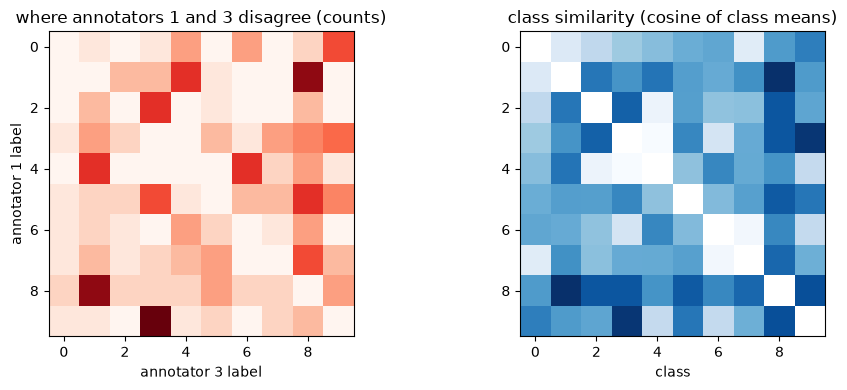

rank correlation between disagreement and class similarity: 0.84
rare class (5 % prevalence), two annotators with 96 % accuracy: raw agreement 0.925, kappa 0.529
time 6 s


In [5]:
cm_ = np.array([X_ALL[Y_ALL == c].mean(0) for c in range(K)])
cm_ /= np.linalg.norm(cm_, axis=1, keepdims=True)
SIM = cm_ @ cm_.T                                           # cosine similarity of class-average images
off = SIM.copy(); np.fill_diagonal(off, -1)
pairs_sorted = sorted([(off[i, j], i, j) for i in range(K) for j in range(i + 1, K)], reverse=True)
print("most look-alike class pairs (cosine similarity of the class means):", [(i, j, round(float(s), 2)) for s, i, j in pairs_sorted[:5]])

def confusion_for(err, guideline=False, beta=25.0):
    W = np.exp(beta * (SIM - 1)); np.fill_diagonal(W, 0)
    W /= W.sum(1, keepdims=True)
    C = err * W
    if guideline:                                            # guidelines clarify the 5 most confusable pairs: those mistakes fall by 70 %
        for s, i, j in pairs_sorted[:5]:
            C[i, j] *= 0.3; C[j, i] *= 0.3
    np.fill_diagonal(C, 0); np.fill_diagonal(C, 1 - C.sum(1))
    return C

def annotate(y, errs, seed, guideline=False):
    r = np.random.default_rng(seed); out = []
    for e in errs:
        C = confusion_for(e, guideline); cum = C[y].cumsum(1)
        out.append((r.random(len(y))[:, None] > cum).sum(1).clip(0, K - 1))
    return np.stack(out)

def majority(A):
    cnt = np.zeros((A.shape[1], K))
    for a in range(A.shape[0]):
        cnt[np.arange(A.shape[1]), A[a]] += 1 + (1e-3 if a == 0 else 0)      # ties go to the first annotator
    return cnt.argmax(1)

errs = [0.08, 0.12, 0.16]
t0 = time.time()
for guideline in [False, True]:
    A = annotate(ytr, errs, 7, guideline); mv = majority(A)
    print(f"\n=== {'with improved guidelines' if guideline else 'original guidelines'} ===")
    print("accuracy against the truth: annotators", [round(float((a == ytr).mean()), 3) for a in A], "majority of 3:", round(float((mv == ytr).mean()), 3))
    pk = {(i, j): cohen_kappa_score(A[i], A[j]) for i in range(3) for j in range(i + 1, 3)}
    pa = {(i, j): float((A[i] == A[j]).mean()) for i in range(3) for j in range(i + 1, 3)}
    print("pairwise raw agreement:", {k: round(v, 3) for k, v in pa.items()})
    print("pairwise Cohen kappa  :", {k: round(v, 3) for k, v in pk.items()})
    acc_ = {}
    for name, lab in [("annotator 1 (8 % errors)", A[0]), ("annotator 3 (16 % errors)", A[2]), ("majority of 3", mv), ("truth", ytr)]:
        acc_[name] = np.mean([mlp(s).fit(Xtr, lab).score(X_test, y_test) for s in range(3)])
    print("model trained on those labels, clean test accuracy:", {k: round(float(v), 3) for k, v in acc_.items()})
    if not guideline:
        conf = np.zeros((K, K))
        for i, j in zip(A[0], A[2]):
            conf[i, j] += 1
        np.fill_diagonal(conf, 0); pass

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
im = ax[0].imshow(conf, cmap="Reds"); ax[0].set_title("where annotators 1 and 3 disagree (counts)"); ax[0].set_xlabel("annotator 3 label"); ax[0].set_ylabel("annotator 1 label"); ax[0].grid(False)
S2 = SIM.copy(); np.fill_diagonal(S2, np.nan)
ax[1].imshow(S2, cmap="Blues"); ax[1].set_title("class similarity (cosine of class means)"); ax[1].set_xlabel("class"); ax[1].grid(False)
plt.tight_layout(); plt.show()
iu = np.triu_indices(K, 1)
print("rank correlation between disagreement and class similarity:", round(float(stats.spearmanr((conf + conf.T)[iu], SIM[iu])[0]), 2))

# why kappa and not raw agreement: two good annotators on a rare class
r = np.random.default_rng(0); truth = (r.random(5000) < 0.05).astype(int)
a1 = np.where(r.random(5000) < 0.04, 1 - truth, truth); a2 = np.where(r.random(5000) < 0.04, 1 - truth, truth)
print(f"rare class (5 % prevalence), two annotators with 96 % accuracy: raw agreement {np.mean(a1 == a2):.3f}, kappa {cohen_kappa_score(a1, a2):.3f}")
print(f"time {time.time() - t0:.0f} s")

**Reading.** The three annotators score 0.92, 0.89 and 0.82 against the truth, and their majority vote 0.97. Pairwise Cohen's kappa is 0.70 to 0.80 against raw agreement of 0.73 to 0.82: with ten balanced classes chance agreement is only about 0.1, so kappa and raw agreement are close. The rare-class example shows when they are not: two annotators who are each 96 % accurate agree on 92.5 % of the items yet have a kappa of only 0.53, because most of that agreement is the easy majority class. The disagreement is **concentrated in look-alike classes** (rank correlation 0.84 between the annotators' disagreement counts and the data-derived class similarity), which is where better guidelines and a second look pay off. The label quality passes straight through to the model: trained on annotator 1 it reaches 0.940, on annotator 3 0.911, on the majority vote 0.960, on the truth 0.976. The majority vote recovers most of the gap for three times the labelling cost. The **improved guidelines** (the five most confusable pairs made 70 % less error-prone, an assumption we chose) lift the kappas to 0.77 to 0.84 and the majority accuracy to 0.985, but the model-level gains are small: 0.926 against 0.911 for the weakest annotator (3 seeds, about one point of spread, so suggestive only) and no visible change for the best annotator or for the majority vote (0.935 against 0.940; 0.961 against 0.960). Two caveats: simulated annotators err independently, which flatters the majority vote because real annotators share systematic mistakes; and in a real project a guideline revision has to be tested like this, with a re-labelled sample, never assumed.

## 6. Leakage, duplicates and group splits

**Data leakage** means information from outside the training data (usually from the test set, or from the future) sneaks into training, so the test score is optimistic and the deployed model disappoints. Two common forms:

* **Duplicate and near-duplicate leakage.** The same item, or a slightly changed copy (a re-exported photo, successive frames of a video, several scans of one patient, the same product listed twice), lands on both sides of a random split. A model that memorises scores well on the test copy without having learned anything general. The fix is a **group split**: all copies of one underlying item stay together on one side.
* **Feature (target) leakage.** A column is available in the training data because of the label, not before it (a field filled in *after* the diagnosis; a file path that encodes the class), and is absent or different in production.

**Part A, duplicates.** We pick 200 base images from the pool, make 5 near-duplicates of each (the same image plus a little pixel noise, standard deviation 0.08), giving 1000 rows in 200 **groups**, and measure the test score of four models under (i) a **random split**, (ii) a **group split**, and (iii) the honest reference, a set of 597 fresh images never seen. Then we try to **find the duplicates without being told the groups**: nearest-neighbour distances, a threshold, and connected components.

**Part B, a leaking feature.** We add one column that is, in the lab where the data was collected, almost the class itself (think "scanner station", with one station per digit), and measure the model in the lab and in "deployment" where the column is unrelated to the class.

In [6]:
t0 = time.time()
rL = np.random.default_rng(5)
base_idx = rL.choice(len(X_pool), 200, replace=False); copies = 5
Xd = np.vstack([np.clip(X_pool[i] + rL.normal(0, 0.08, (copies, 64)), 0, 1) for i in base_idx])
yd = np.repeat(y_pool[base_idx], copies); gd = np.repeat(np.arange(200), copies)

models6 = {"1-nearest-neighbour": lambda s: KNeighborsClassifier(1), "random forest": lambda s: RandomForestClassifier(100, random_state=s, n_jobs=1),
           "MLP": lambda s: mlp(s), "logistic regression": lambda s: logreg()}
def leak_task(seed):
    rs = np.random.default_rng(seed); perm = rs.permutation(len(Xd)); te_r, tr_r = perm[:200], perm[200:]
    tr_g, te_g = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(Xd, yd, gd))
    o = {}
    for n, mk in models6.items():
        o[n] = (mk(seed).fit(Xd[tr_r], yd[tr_r]).score(Xd[te_r], yd[te_r]),
                (m := mk(seed).fit(Xd[tr_g], yd[tr_g])).score(Xd[te_g], yd[te_g]),
                m.score(X_test, y_test))
    return o
L = pmap(leak_task, range(5))
print(f"{'model':22s} {'random split':>13s} {'group split':>12s} {'fresh images':>13s}  (mean of 5 seeds; fresh = model of the group split)")
for n in models6:
    v = np.array([l[n] for l in L]).mean(0)
    print(f"{n:22s} {v[0]:13.3f} {v[1]:12.3f} {v[2]:13.3f}")

# finding the duplicates without the groups
nn = NearestNeighbors(n_neighbors=2).fit(Xd); dist, ind = nn.kneighbors(Xd); d1, j1 = dist[:, 1], ind[:, 1]
same = gd[j1] == gd
D = pairwise_distances(Xd)
same_g = gd[:, None] == gd[None, :]
other = np.where(same_g, np.inf, D).min(1); copy_d = np.where(same_g & ~np.eye(len(Xd), dtype=bool), D, np.inf).min(1)
print(f"\ndistance to the nearest true copy: median {np.median(copy_d):.2f}; to the nearest image of another group: median {np.median(other):.2f}, 1st percentile {np.percentile(other, 1):.2f}")
iu = np.triu_indices(len(Xd), 1); true_pair = (gd[:, None] == gd[None, :])[iu]
best = None
print(f"{'threshold':>9s} {'precision':>10s} {'recall':>8s} {'F1':>6s}")
for tau in [0.6, 0.9, 1.2, 1.5, 1.8, 2.1]:
    pr = D[iu] < tau; tp = (pr & true_pair).sum(); p = tp / max(pr.sum(), 1); rc = tp / true_pair.sum(); f = 2 * p * rc / max(p + rc, 1e-9)
    print(f"{tau:9.1f} {p:10.3f} {rc:8.3f} {f:6.3f}")
    if best is None or f > best[1]:
        best = (tau, f)
tau = best[0]
ii, jj = np.where(np.triu(D < tau, 1))
ncomp, found = connected_components(coo_matrix((np.ones(len(ii)), (ii, jj)), shape=(len(Xd),) * 2), directed=False)
print(f"chosen threshold {tau} (best F1 on a labelled sample of pairs): {ncomp} groups found, true number 200")
fr = []
for s in range(5):
    tr_f, te_f = next(GroupShuffleSplit(1, test_size=0.2, random_state=s).split(Xd, yd, found))
    fr.append(KNeighborsClassifier(1).fit(Xd[tr_f], yd[tr_f]).score(Xd[te_f], yd[te_f]))
print(f"1-NN with the groups we discovered ourselves: {np.mean(fr):.3f}   (true groups: {np.mean([l['1-nearest-neighbour'][1] for l in L]):.3f}, random split: {np.mean([l['1-nearest-neighbour'][0] for l in L]):.3f})")

# how many near-duplicates cross the raw digits train/test split?
dtp, _ = NearestNeighbors(n_neighbors=1).fit(X_pool).kneighbors(X_test)
print(f"raw digits, test image to its nearest training image: closest {dtp.min():.2f}, test images closer than 0.6: {int((dtp[:, 0] < 0.6).sum())}, closer than {tau}: {int((dtp[:, 0] < tau).sum())} of {len(X_test)}")

# Part B: a leaking feature
r2 = np.random.default_rng(1)
leak = lambda y: (y + r2.normal(0, 0.1, len(y)))[:, None]
Xl_tr, Xl_te = np.hstack([Xtr, leak(ytr)]), np.hstack([X_test, leak(y_test)])
Xl_dep = np.hstack([X_test, r2.uniform(0, 9, (len(X_test), 1))])          # in deployment the column means nothing
rf_leak = RandomForestClassifier(200, random_state=0, n_jobs=1).fit(Xl_tr, ytr)
rf_clean = RandomForestClassifier(200, random_state=0, n_jobs=1).fit(Xtr, ytr)
print(f"\nrandom forest WITH the leaking column: lab test {rf_leak.score(Xl_te, y_test):.3f}, deployment {rf_leak.score(Xl_dep, y_test):.3f}")
print(f"random forest WITHOUT the column     : lab test {rf_clean.score(X_test, y_test):.3f}, deployment {rf_clean.score(X_test, y_test):.3f}")
imp = rf_leak.feature_importances_
print(f"importance of the leaking column: {imp[-1]:.3f} (the 64 pixels average {imp[:-1].mean():.4f} each)")
print(f"time {time.time() - t0:.0f} s")

model                   random split  group split  fresh images  (mean of 5 seeds; fresh = model of the group split)
1-nearest-neighbour            1.000        0.957         0.950
random forest                  1.000        0.917         0.933
MLP                            1.000        0.938         0.924
logistic regression            0.992        0.933         0.921

distance to the nearest true copy: median 0.62; to the nearest image of another group: median 1.37, 1st percentile 0.79
threshold  precision   recall     F1
      0.6      1.000    0.136  0.239
      0.9      0.986    0.997  0.991
      1.2      0.750    1.000  0.857
      1.5      0.367    1.000  0.537
      1.8      0.172    1.000  0.294
      2.1      0.088    1.000  0.162
chosen threshold 0.9 (best F1 on a labelled sample of pairs): 196 groups found, true number 200
1-NN with the groups we discovered ourselves: 0.922   (true groups: 0.957, random split: 1.000)
raw digits, test image to its nearest training image: c


random forest WITH the leaking column: lab test 0.998, deployment 0.911
random forest WITHOUT the column     : lab test 0.956, deployment 0.956
importance of the leaking column: 0.177 (the 64 pixels average 0.0129 each)
time 3 s


**Reading.** **Part A.** With a random split, every model scores 1.000 (logistic regression 0.992): the test copy of an image is nearly identical to a training copy, so memorisation is rewarded. With a group split the same models score 0.92 to 0.96, and on 597 fresh images they score 0.92 to 0.95, so the group-split estimate is within about 1.5 points of the honest one (1-nearest-neighbour 0.957 against 0.950, forest 0.917 against 0.933, network 0.938 against 0.924, logistic regression 0.933 against 0.921) while the random-split estimate overstates by 4 to 8 points. The duplicates themselves are easy to find when they are as close as ours: the median distance to the nearest true copy is 0.62, to the nearest image of another group 1.37 (first percentile 0.79), and a threshold of 0.9 finds the copy pairs with precision 0.986 and recall 0.997. Connected components at that threshold produce 196 groups against 200 true ones. Using the groups we **discovered** gave 0.922 for the 1-nearest-neighbour model, against 0.957 with the true groups: a few groups were merged, which makes the test set harder, so the estimate errs on the conservative side; we did not isolate the rest of the difference from split noise. A threshold chosen on injected copies does not transfer by itself: on the raw digits the closest test-to-training distance is 0.50 and only 6 of 597 test images lie closer than the 0.6 level of our copies (133 closer than 0.9), which are neighbours of the same digit and not duplicates. Those 6 deserve a look by eye, and the lesson is to **inspect the closest pairs** instead of trusting a number. **Part B.** The forest with the leaking column scores 0.998 in the lab and 0.911 in deployment, against 0.956 in both for the honest model: the leak buys 4 points in the lab and costs 4.5 points where it matters. Its importance (0.177) is 14 times that of an average pixel (0.0129), a cheap check worth running on every feature of every project. The real-world analogues are scans of one patient on both sides of a split, frames of one video, or a file path that encodes the class.

## 7. Learning curves: more data or a better model?

A **learning curve** plots the error of a model as a function of the training set size $n$. It answers the practical question "if I pay for more labels, how much will I gain?" before paying. We train on random subsets of the pool of sizes 30 to 1000 and test on the 597 clean test images, with **20 random subsets per size** so that we can draw a **confidence band** (the mean plus or minus 1.96 standard errors, the standard error being the spread of the 20 runs divided by $\sqrt{20}$). Caveat: subsets of size 1000 drawn from a pool of 1200 overlap heavily, so the band at the largest size is too narrow.

Two readings of a curve:

* **Gap between training and test error**: a large gap means the model is limited by data (more data or more regularisation helps); training error that is itself high means the model is limited by capacity or by label noise (more data of the same kind will not help).
* **Shape**: test error often follows a **power law** $\varepsilon(n) = a\,n^{-b} + c$, where $c$ is the error floor that infinite data would not remove (noise, model limits), $a$ a scale and $b > 0$ the rate. We fit it to the sizes up to 500 only and **check the prediction at $n = 1000$**, which we also measured. A fit that cannot predict a point it has not seen should not be used to plan a data purchase.

We draw curves for two models, and for the network trained on labels with 30 % symmetric noise, where the floor should be visibly higher.

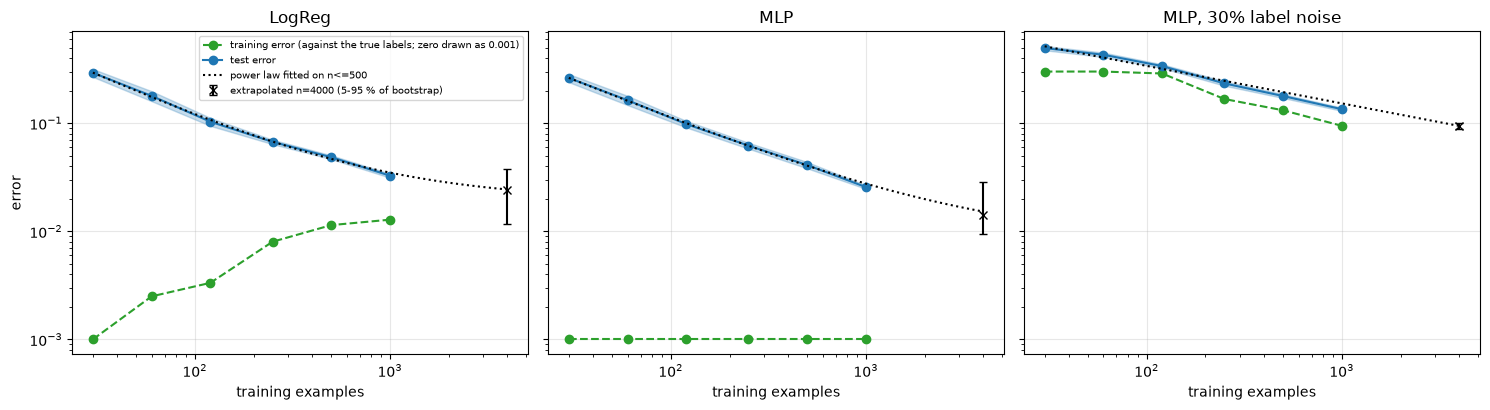

model    noise  floor c  rate b  err@500  err@1000 measured  fit predicted @1000         90% band   extrapolated @4000  train err@1000
LogReg      0%    0.019    0.82    0.048       0.033 ±0.001                0.035 [0.028,0.043]    0.024 [0.012,0.037]           0.013
MLP         0%    0.008    0.73    0.041       0.026 ±0.001                0.028 [0.024,0.036]    0.014 [0.009,0.028]           0.000
MLP        30%    0.000    0.35    0.178       0.135 ±0.005                0.152 [0.145,0.160]    0.094 [0.088,0.101]           0.094
time 9 s


In [7]:
t0 = time.time()
sizes = [30, 60, 120, 250, 500, 1000]; reps = 20
def lc_task(args):
    name, n, rep, rho = args
    rs = np.random.default_rng(10000 * rep + n); idx = rs.choice(len(X_pool), n, replace=False)
    y = flip_sym(y_pool[idx], rho, 7 * rep + n) if rho else y_pool[idx]
    m = (logreg() if name == "LogReg" else mlp(rep)).fit(X_pool[idx], y)
    return 1 - m.score(X_pool[idx], y_pool[idx]), 1 - m.score(X_test, y_test)
curves = {("LogReg", 0): None, ("MLP", 0): None, ("MLP", 0.3): None}
jobs = [(nm, n, rp, rho) for (nm, rho) in curves for n in sizes for rp in range(reps)]
lc = dict(zip(jobs, pmap(lc_task, jobs)))
def power(n, a, b, c):
    return a * np.power(n, -b) + c

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
summary = []
for a_, (nm, rho) in zip(ax, curves):
    tr = np.array([[lc[(nm, n, rp, rho)][0] for rp in range(reps)] for n in sizes])
    te = np.array([[lc[(nm, n, rp, rho)][1] for rp in range(reps)] for n in sizes])
    m, se = te.mean(1), te.std(1, ddof=1) / np.sqrt(reps)
    a_.plot(sizes, np.maximum(tr.mean(1), 1e-3), "C2--o", label="training error (against the true labels; zero drawn as 0.001)")
    a_.plot(sizes, m, "C0-o", label="test error"); a_.fill_between(sizes, m - 1.96 * se, m + 1.96 * se, color="C0", alpha=0.25)
    fit_n = np.array(sizes[:5]); boots = []
    rb = np.random.default_rng(0)
    for _ in range(200):
        pick = rb.integers(0, reps, reps); mb = te[:5][:, pick].mean(1)
        try:
            p, _ = curve_fit(power, fit_n, mb, p0=[1.0, 0.5, 0.01], bounds=([0, 0.05, 0], [50, 3, 0.5]), maxfev=5000)
            boots.append(power(np.array([1000, 4000]), *p))
        except Exception:
            pass
    boots = np.array(boots); p, _ = curve_fit(power, fit_n, m[:5], p0=[1.0, 0.5, 0.01], bounds=([0, 0.05, 0], [50, 3, 0.5]), maxfev=5000)
    xs = np.logspace(np.log10(30), np.log10(4000), 60); a_.plot(xs, power(xs, *p), "k:", label=f"power law fitted on n<=500")
    a_.errorbar([4000], [np.median(boots[:, 1])], [[np.median(boots[:, 1]) - np.percentile(boots[:, 1], 5)], [np.percentile(boots[:, 1], 95) - np.median(boots[:, 1])]], fmt="kx", capsize=3, label="extrapolated n=4000 (5-95 % of bootstrap)")
    a_.set_xscale("log"); a_.set_yscale("log"); a_.set_xlabel("training examples"); a_.set_title(f"{nm}" + (f", {rho:.0%} label noise" if rho else ""))
    summary.append((nm, rho, p, m[4], m[5], se[5], power(1000, *p), np.percentile(boots[:, 0], [5, 95]), np.median(boots[:, 1]), np.percentile(boots[:, 1], [5, 95]), tr.mean(1)[5]))
ax[0].set_ylabel("error"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"{'model':8s} {'noise':>5s} {'floor c':>8s} {'rate b':>7s} {'err@500':>8s} {'err@1000 measured':>18s} {'fit predicted @1000':>20s} {'90% band':>16s} {'extrapolated @4000':>20s} {'train err@1000':>15s}")
for nm, rho, p, e500, e1000, se1000, pred, band, e4000, b4000, trn in summary:
    print(f"{nm:8s} {rho:5.0%} {p[2]:8.3f} {p[1]:7.2f} {e500:8.3f} {e1000:11.3f} ±{1.96 * se1000:.3f} {pred:20.3f} [{band[0]:.3f},{band[1]:.3f}] {e4000:8.3f} [{b4000[0]:.3f},{b4000[1]:.3f}] {trn:15.3f}")
print(f"time {time.time() - t0:.0f} s")

**Reading.** The test error of both models falls almost linearly on the log-log plot over the whole range, so neither has plateaued at 1000 examples: the network goes from 0.041 at 500 to 0.026 at 1000 (a 37 % cut for doubling the data) and logistic regression from 0.048 to 0.033. The network is better than logistic regression at every size, and its training error is zero while the test error is 2.6 %, the signature of a model limited by data and not by capacity: **here, collecting more clean data should help**, by about a third per doubling according to the measured slope. The power-law fit (floor $c$ = 0.008 for the network and 0.019 for logistic regression, rate $b$ about 0.7 to 0.8) predicted the held-out size 1000 correctly for the two clean cases: the predictions 0.035 and 0.028 lie inside their 90 % bootstrap bands and within 0.2 points of the measurements 0.033 and 0.026. For the noisy case it **failed**: predicted 0.152 with band 0.145 to 0.160 against a measured 0.135, so the extrapolation to 4000 (0.094) is too pessimistic and its band too narrow; the fitted power law was not the right shape for that curve, which falls with a shallower slope ($b$ = 0.35). Reading the plot, 1000 examples with 30 % noise are worth roughly 80 to 100 clean ones. The extrapolations to 4000 (0.024 and 0.014 with wide bands) are a guide to the order of magnitude, not a promise. Caveat: subsets of size 1000 from a pool of 1200 overlap heavily, so the band at that size is too narrow, and the toy has a very smooth curve; real learning curves are noisier and often bend.

## 8. The value of each data point

Not every training example is worth the same: some carry the pattern, some are redundant, some are mislabelled and *hurt*. **Data valuation** assigns each training point a number for its contribution. Two classic definitions, with a **utility** $U(S)$ = validation accuracy of a model trained on the subset $S$ of the training set $D$ ($n = |D|$ points):

* **Leave-one-out** (LOO): $v^{\text{LOO}}_i = U(D) - U(D \setminus \{i\})$. Cheap ($n+1$ fits), but if a point has a twin, removing either changes nothing, so both look worthless.
* **Data Shapley** (Ghorbani and Zou, 2019): the average marginal contribution $U(S \cup \{i\}) - U(S)$ of point $i$ over **all orders** in which the data could be assembled, the Shapley value from cooperative game theory,

$$v_i = \frac{1}{n}\sum_{S \subseteq D \setminus \{i\}} \binom{n-1}{|S|}^{-1} \big[U(S \cup \{i\}) - U(S)\big].$$

The sum has $2^{n-1}$ terms, so we estimate it by **Monte Carlo over random permutations**: shuffle the data, add points one at a time, and record each point's marginal gain; average over many shuffles (the *truncated* Monte Carlo variant of the paper also stops early when the gain becomes negligible, which we skip because our set is tiny); we use 240 permutations.

Toy: the hardest digit pair in the data, 4 versus 9. Training set of 36 images of which 6 have **flipped labels**; a 120 image validation set defines $U$; the remaining images are the test set. We test whether the value ranks flipped points last, and whether **removing the lowest-valued points** improves the model on the test set more than removing random ones, and whether removing the highest-valued points hurts.

U(all 36 points) = 0.925; Shapley values sum to 0.425 (efficiency: U(all) - U(empty) = 0.425)
agreement between two independent halves of the permutations (Spearman): 0.79
AUROC of 'low value = flipped label':  LOO 0.72,  Shapley 1.00
mean value of the 6 flipped points: LOO -0.0014 vs +0.0153 others;  Shapley -0.0454 vs +0.0233 others
rank correlation LOO vs Shapley: 0.55


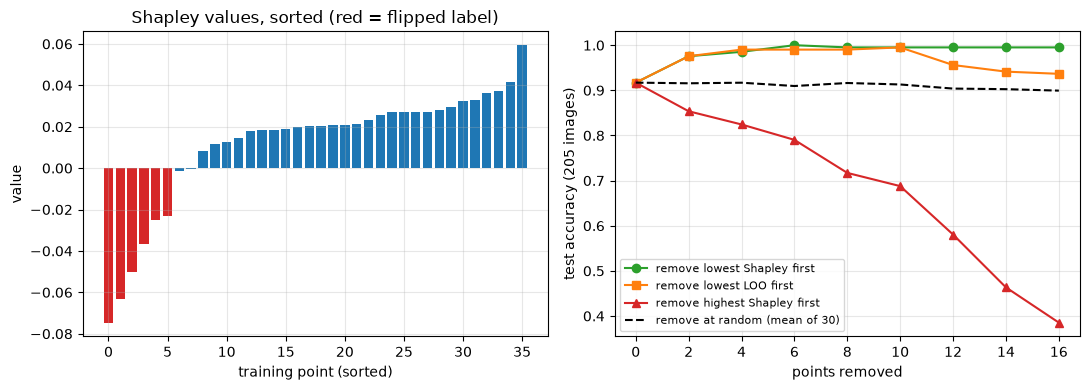

test accuracy after removing k points, lowest Shapley first     {0: 0.917, 2: 0.976, 4: 0.985, 6: 1.0, 8: 0.995, 10: 0.995, 12: 0.995, 14: 0.995, 16: 0.995}
test accuracy after removing k points, lowest LOO first         {0: 0.917, 2: 0.976, 4: 0.99, 6: 0.99, 8: 0.99, 10: 0.995, 12: 0.956, 14: 0.941, 16: 0.937}
test accuracy after removing k points, highest Shapley first    {0: 0.917, 2: 0.854, 4: 0.824, 6: 0.79, 8: 0.717, 10: 0.688, 12: 0.58, 14: 0.463, 16: 0.385}
random removal (mean of 30)                                                {0: 0.917, 2: 0.916, 4: 0.917, 6: 0.91, 8: 0.916, 10: 0.913, 12: 0.904, 14: 0.903, 16: 0.899}
time 5 s


In [8]:
t0 = time.time()
m49 = np.isin(Y_ALL, [4, 9]); X49, y49 = X_ALL[m49], (Y_ALL[m49] == 9).astype(int)
r8 = np.random.default_rng(3); perm = r8.permutation(len(X49))
itr, iva, ite = perm[:36], perm[36:156], perm[156:]
Xv, yv_true = X49[itr], y49[itr]; yv = yv_true.copy()
flipped = r8.choice(36, 6, replace=False); yv[flipped] = 1 - yv[flipped]
Xval, yval, Xt49, yt49 = X49[iva], y49[iva], X49[ite], y49[ite]

def util(idx, Xs=None, ys=None):
    idx = np.asarray(idx, int)
    if len(idx) < 2 or len(np.unique(yv[idx])) < 2:
        return 0.5
    return LogisticRegression(max_iter=100).fit(Xv[idx], yv[idx]).score(Xval, yval)

full = np.arange(36); U_full = util(full)
loo = np.array([U_full - util(np.delete(full, i)) for i in range(36)])

def shap_task(args):
    seed, nperm = args
    rs = np.random.default_rng(seed); vals = np.zeros(36)
    for _ in range(nperm):
        p = rs.permutation(36); prev = 0.5
        for t in range(36):
            u = util(p[:t + 1]); vals[p[t]] += u - prev; prev = u
    return vals / nperm
parts = pmap(shap_task, [(s, 60) for s in range(4)])
shap = np.mean(parts, 0)
half_corr = stats.spearmanr(np.mean(parts[:2], 0), np.mean(parts[2:], 0))[0]
truth = np.zeros(36, bool); truth[flipped] = True
print(f"U(all 36 points) = {U_full:.3f}; Shapley values sum to {shap.sum():.3f} (efficiency: U(all) - U(empty) = {U_full - 0.5:.3f})")
print(f"agreement between two independent halves of the permutations (Spearman): {half_corr:.2f}")
print(f"AUROC of 'low value = flipped label':  LOO {roc_auc_score(truth, -loo):.2f},  Shapley {roc_auc_score(truth, -shap):.2f}")
print(f"mean value of the 6 flipped points: LOO {loo[truth].mean():+.4f} vs {loo[~truth].mean():+.4f} others;  Shapley {shap[truth].mean():+.4f} vs {shap[~truth].mean():+.4f} others")
print(f"rank correlation LOO vs Shapley: {stats.spearmanr(loo, shap)[0]:.2f}")

def test_after_removal(order, k):
    keep = np.setdiff1d(full, order[:k]);
    if len(np.unique(yv[keep])) < 2: return 0.5
    return LogisticRegression(max_iter=100).fit(Xv[keep], yv[keep]).score(Xt49, yt49)
ks = list(range(0, 17, 2))
low = np.argsort(shap); high = np.argsort(-shap); lo_loo = np.argsort(loo)
rand = np.mean([[test_after_removal(np.random.default_rng(s).permutation(36), k) for k in ks] for s in range(30)], 0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(np.arange(36), shap[np.argsort(shap)], color=["C3" if truth[i] else "C0" for i in np.argsort(shap)]); ax[0].set_title("Shapley values, sorted (red = flipped label)"); ax[0].set_xlabel("training point (sorted)"); ax[0].set_ylabel("value")
ax[1].plot(ks, [test_after_removal(low, k) for k in ks], "C2-o", label="remove lowest Shapley first")
ax[1].plot(ks, [test_after_removal(lo_loo, k) for k in ks], "C1-s", label="remove lowest LOO first")
ax[1].plot(ks, [test_after_removal(high, k) for k in ks], "C3-^", label="remove highest Shapley first")
ax[1].plot(ks, rand, "k--", label="remove at random (mean of 30)")
ax[1].set_xlabel("points removed"); ax[1].set_ylabel(f"test accuracy ({len(yt49)} images)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
for nm_, o_ in [("lowest Shapley first", low), ("lowest LOO first", lo_loo), ("highest Shapley first", high)]:
    print(f"test accuracy after removing k points, {nm_:24s}", {k: round(float(test_after_removal(o_, k)), 3) for k in ks})
print(f"{'random removal (mean of 30)':74s}", {k: round(float(v), 3) for k, v in zip(ks, rand)})
print(f"time {time.time() - t0:.0f} s")

**Reading.** The Shapley values add up to the total gain $U(D) - U(\emptyset) = 0.425$ (the efficiency property, a good check on the estimator), and two independent halves of the permutations rank the points with a Spearman correlation of 0.79, so the estimate is usable but not exact with 240 permutations. **Shapley ranked all 6 flipped labels at the bottom (AUROC 1.00); leave-one-out got 0.72**, and the two rankings agree only moderately (rank correlation 0.55). The flipped points have a mean Shapley value of $-0.045$ against $+0.023$ for the others. The removal experiment shows the practical value: dropping the 2, 4 and 6 lowest-valued points lifts the test accuracy from 0.917 to 0.976, 0.985 and 1.000 (205 test images, so one image is 0.5 points), whereas removing random points leaves it at 0.90 to 0.92, and removing the *highest*-valued points degrades it steadily to 0.385 at 16 removals. Leave-one-out helps up to 10 removals (0.995) and then starts to remove useful points (0.937 at 16), while Shapley stays at 0.995. The cost difference is large: 240 permutations times 36 fits, about 8600 model fits, against 37 for leave-one-out. This toy has 36 points and a fast model; for real datasets the exact sum is out of reach and one uses cheaper approximations (nearest-neighbour Shapley, influence functions, or the training-loss dynamics), so the toy shows what a good valuation *should* find, not that it is cheap.

## 9. Active learning

Labels are the expensive part. **Active learning** lets the model choose which unlabelled examples a person should label next, instead of labelling at random (Settles, 2009). The loop: train on what is labelled, score the unlabelled pool, ask for labels on the most useful $b$ examples (the **batch**), repeat. Strategies:

* **random**: the baseline every active method must beat, and the one that often wins when the model is weak or the budget is tiny;
* **uncertainty (entropy)**: pick examples where the predicted distribution is most spread out, $H = -\sum_k p_k \ln p_k$;
* **margin**: pick examples where the top two class probabilities are closest;
* **diversity (k-center)**: ignore the model and pick examples far from everything already labelled (greedy farthest-point choice), which covers the input space;
* **hybrid**: take the $5b$ most uncertain, then choose $b$ of them that are far apart (so that a batch is not ten copies of the same confusing region).

We start from 20 random labels, add 10 per round up to 200, with a logistic regression, on the 1200 image pool, scoring on the clean test set. All curves are the mean of **20 seeds** (different initial sets), with a 90 % band. The headline number is the **labelling budget** each strategy needs to reach a target accuracy, and the saving relative to random.

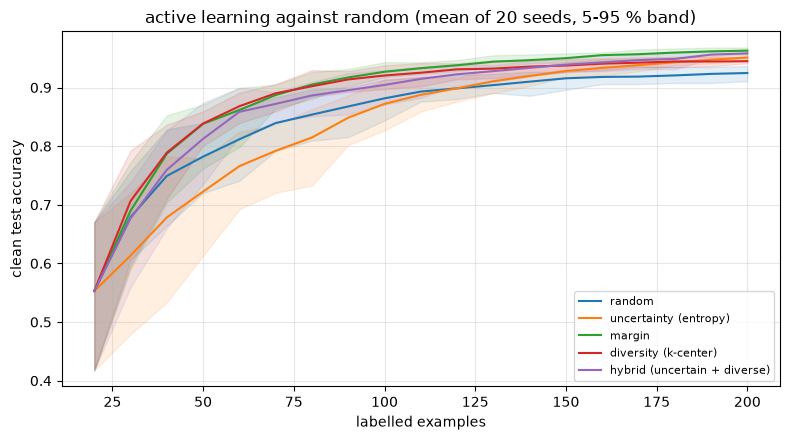

strategy                        acc@60  acc@100  acc@200   labels to reach 0.85  saving   labels to reach 0.90  saving
random                           0.812    0.882    0.925                     80      0%                   130      0%
uncertainty (entropy)            0.766    0.872    0.951                    100    -25%                   130      0%
margin                           0.862    0.927    0.963                     60     25%                    80     38%
diversity (k-center)             0.868    0.921    0.945                     60     25%                    80     38%
hybrid (uncertain + diverse)     0.859    0.904    0.958                     60     25%                   100     23%
seed spread (sd of accuracy at 100 labels): {'random': 0.022, 'uncertainty (entropy)': 0.029, 'margin': 0.008, 'diversity (k-center)': 0.013, 'hybrid (uncertain + diverse)': 0.019}
paired difference to random at 100 labels (mean ± standard error, paired t-test): {'uncertainty (entropy)': '-

In [9]:
t0 = time.time()
D_pool = pairwise_distances(X_pool)
def kcenter(cand, lab, b):
    mind = D_pool[np.ix_(cand, lab)].min(1); pick = []
    for _ in range(b):
        j = int(mind.argmax()); pick.append(cand[j]); mind = np.minimum(mind, D_pool[cand, cand[j]])
    return pick

def al_task(args):
    strat, seed = args
    r = np.random.default_rng(seed); lab = list(r.choice(len(X_pool), 20, replace=False)); accs = []; budget = 200; b = 10
    while True:
        m = LogisticRegression(max_iter=200).fit(X_pool[lab], y_pool[lab]); accs.append(m.score(X_test, y_test))
        if len(lab) >= budget:
            break
        unl = np.setdiff1d(np.arange(len(X_pool)), lab)
        if strat == "random":
            pick = list(r.choice(unl, b, replace=False))
        elif strat == "diversity (k-center)":
            pick = kcenter(unl, np.array(lab), b)
        else:
            P = np.zeros((len(unl), K)); P[:, m.classes_] = m.predict_proba(X_pool[unl])
            if strat == "uncertainty (entropy)":
                pick = list(unl[np.argsort(-(-(P * np.log(P + 1e-12)).sum(1)))[:b]])
            elif strat == "margin":
                s = np.sort(P, 1); pick = list(unl[np.argsort(s[:, -1] - s[:, -2])[:b]])
            else:
                ent = -(P * np.log(P + 1e-12)).sum(1); cand = unl[np.argsort(-ent)[:5 * b]]
                pick = kcenter(cand, np.array(lab), b)
        lab += pick
    return accs

strats = ["random", "uncertainty (entropy)", "margin", "diversity (k-center)", "hybrid (uncertain + diverse)"]
jobs = [(s, sd) for s in strats for sd in range(20)]
al = dict(zip(jobs, pmap(al_task, jobs)))
grid = np.arange(20, 201, 10)
fig, ax = plt.subplots(figsize=(8, 4.5)); curves_al = {}
for i, s in enumerate(strats):
    A = np.array([al[(s, sd)] for sd in range(20)]); curves_al[s] = A
    ax.plot(grid, A.mean(0), color=f"C{i}", label=s); ax.fill_between(grid, np.percentile(A, 5, 0), np.percentile(A, 95, 0), color=f"C{i}", alpha=0.12)
ax.set_xlabel("labelled examples"); ax.set_ylabel("clean test accuracy"); ax.legend(fontsize=8); ax.set_title("active learning against random (mean of 20 seeds, 5-95 % band)")
plt.tight_layout(); plt.show()
print(f"{'strategy':30s} {'acc@60':>7s} {'acc@100':>8s} {'acc@200':>8s}  {'labels to reach 0.85':>21s} {'saving':>7s}  {'labels to reach 0.90':>21s} {'saving':>7s}")
def first(A, thr):
    mm = A.mean(0); hit = np.where(mm >= thr)[0]
    return grid[hit[0]] if len(hit) else None
base = {t: first(curves_al["random"], t) for t in (0.85, 0.90)}
for s in strats:
    A = curves_al[s]; row = f"{s:30s} {A[:, 4].mean():7.3f} {A[:, 8].mean():8.3f} {A[:, -1].mean():8.3f} "
    for t in (0.85, 0.90):
        f = first(A, t)
        sv = (f"{1 - f / base[t]:7.0%}" if f and base[t] else "    n/a")
        row += f" {str(f) if f else '>200':>21s} {sv}"
    print(row)
print("seed spread (sd of accuracy at 100 labels):", {s: round(float(curves_al[s][:, 8].std()), 3) for s in strats})
pdiff = {}
for s_ in strats[1:]:
    d = curves_al[s_][:, 8] - curves_al["random"][:, 8]            # same seed = same initial labelled set
    pdiff[s_] = f"{d.mean():+.3f} ± {d.std(ddof=1) / np.sqrt(len(d)):.3f} (p = {stats.ttest_rel(curves_al[s_][:, 8], curves_al['random'][:, 8]).pvalue:.3f})"
print("paired difference to random at 100 labels (mean ± standard error, paired t-test):", pdiff)
print(f"time {time.time() - t0:.0f} s")

**Reading.** Averaged over 20 seeds, **margin and diversity sampling reach 0.90 accuracy with 80 labels where random needs 130**, a saving of 38 %, and 0.85 with 60 labels against 80 (25 %); the hybrid saves 25 % and 23 %. At 100 labels the paired differences to random (same initial labels per seed) are $+0.045 \pm 0.006$ for margin, $+0.039 \pm 0.005$ for diversity and $+0.023 \pm 0.007$ for the hybrid, with the spread across seeds between 0.8 and 2.9 points. **Plain entropy sampling is no better than random** early on (0.766 against 0.812 at 60 labels, a paired difference at 100 labels of $-0.009 \pm 0.009$): the ten most uncertain examples sit in the same confusing region, so a batch is redundant, and with 20 labels the model's uncertainty is itself unreliable (the cold-start problem). It overtakes random later (0.951 against 0.925 at 200 labels), which shows that the ranking of strategies depends on the budget. Our hybrid, uncertain candidates then farthest-point choice, did not beat margin or pure diversity on this data, so "combine them" is a hypothesis to test and not a rule. The first-crossing budgets have a resolution of 10 labels, which explains why two strategies with different curves can share a number. Where the toy differs: a 1200 image pool and a logistic regression make selection cheap and retraining instant; real pools have millions of items, models take hours to retrain, annotators err (section 5) and the item the model finds most uncertain is also the one a human finds hardest to label.

## 10. Augmentation, synthetic data and model collapse

**Augmentation** makes new training examples by applying changes that **should not change the label**: shift a digit by one pixel, rotate it a few degrees, add a little noise. It injects domain knowledge ("a 7 is still a 7 if it moves a little") and it is the cheapest way to grow a small dataset. Its risk is exactly the knowledge: an augmentation that changes the label (rotating a 6 by 180 degrees gives a 9) teaches the wrong thing.

**Synthetic data** goes further: train a generative model on the real data and sample new examples from it. It is attractive when real data is scarce, private or imbalanced, but it can only recombine what the generator learned, and **what is not in the real sample is not in the synthetic one**.

**Model collapse** (Shumailov et al., 2023, 2024) is what happens when this is iterated: model $G_{t+1}$ is trained on samples generated by $G_t$, which was trained on samples generated by $G_{t-1}$, and so on. Each generation estimates a distribution from a finite sample, so rare events (the tails) are missed with some probability, and once missing they never come back. The distribution narrows and drifts. This matters because web-scale models increasingly train on text and images that earlier models produced. A follow-up (Gerstgrasser et al., 2024) showed that **accumulating** real data alongside synthetic data, instead of replacing it, avoids the collapse in their setting.

We run three small experiments. **A**: augmentations with a model trained on 150 real digits, including a harmful one. **B**: synthetic digits sampled from a per-class Gaussian fitted to the same 150 images. **C**: the collapse toy: a one-dimensional distribution made of a main bump (85 % of the mass, centred at 0) and a rare bump (15 %, centred at 5); each generation fits a two-component Gaussian mixture to 60 points and the next generation trains on 60 points sampled from it. We compare **replace** (train only on the previous generation's samples), **accumulate** (keep the real sample and all previous generations) and **20 % fresh real** (each generation mixes 20 % newly collected real data).

Parts A and B: clean test accuracy of an MLP (mean ± sd of 10 seeds; each augmentation adds 6 modified copies of the 150 images)
  150 real                                 0.914 ± 0.014
  + shifts of 1 pixel only                 0.908 ± 0.013
  + rotations up to 12 degrees only        0.904 ± 0.014
  + pixel noise only                       0.914 ± 0.012
  + all three                              0.890 ± 0.013
  + all three and 180 degree turns (changes labels) 0.875 ± 0.012
  + all three and mirror image (changes labels) 0.860 ± 0.015
  300 real (twice the labels)              0.951 ± 0.007
  150 real + 600 synthetic Gaussian        0.914 ± 0.006
  600 synthetic only                       0.909 ± 0.010


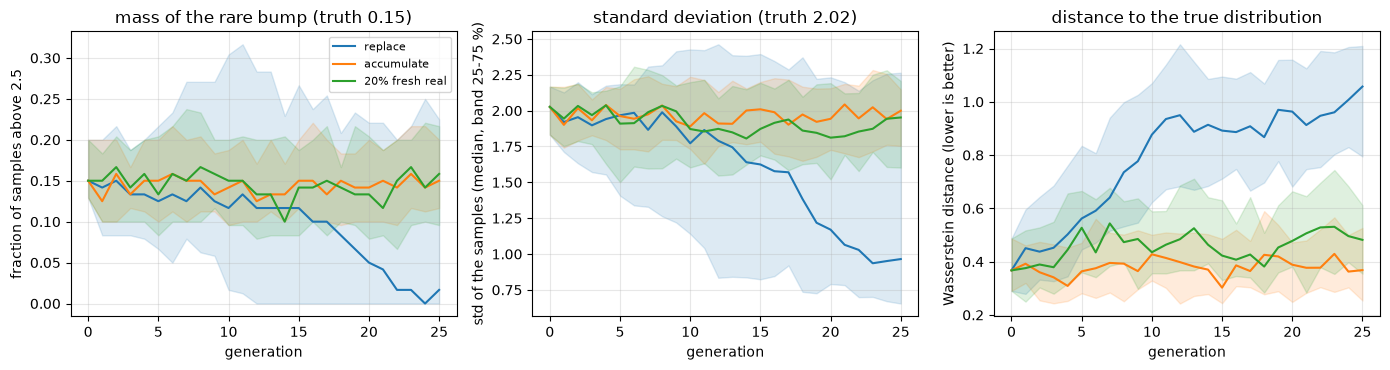

true std of the mixture: 2.02; true rare mass 0.154
regime             rare mass gen0  gen25 mean  gen25 median   runs with rare bump lost  std gen0 gen25 med  W1 gen0 gen25 med
replace                     0.160       0.132         0.017                   20 of 40      1.99    0.96     0.41    1.06
accumulate                  0.160       0.153         0.150                    0 of 40      1.99    2.00     0.41    0.37
20% fresh real              0.160       0.168         0.158                    0 of 40      1.99    1.95     0.41    0.48
time 12 s


In [10]:
t0 = time.time()
def augment(x, rs, kinds):
    im = x.reshape(8, 8)
    if "shift" in kinds: im = ndimage.shift(im, rs.integers(-1, 2, 2), order=1, mode="constant")
    if "rotate" in kinds: im = ndimage.rotate(im, rs.uniform(-12, 12), reshape=False, order=1, mode="constant")
    if "noise" in kinds: im = im + rs.normal(0, 0.05, im.shape)
    if "flip180" in kinds and rs.random() < 0.5: im = np.rot90(im, 2)
    if "mirror" in kinds and rs.random() < 0.5: im = im[:, ::-1]
    return np.clip(im, 0, 1).ravel()

def aug_task(seed):
    rs = np.random.default_rng(seed); idx = rs.choice(len(X_pool), 150, replace=False); X0, y0 = X_pool[idx], y_pool[idx]
    out = {}
    out["150 real"] = mlp(seed).fit(X0, y0).score(X_test, y_test)
    for name, kinds in [("+ shifts of 1 pixel only", ["shift"]), ("+ rotations up to 12 degrees only", ["rotate"]), ("+ pixel noise only", ["noise"]),
                        ("+ all three", ["shift", "rotate", "noise"]), ("+ all three and 180 degree turns (changes labels)", ["shift", "rotate", "noise", "flip180"]),
                        ("+ all three and mirror image (changes labels)", ["shift", "rotate", "noise", "mirror"])]:
        Xa = np.vstack([X0] + [np.array([augment(x, rs, kinds) for x in X0]) for _ in range(6)]); ya = np.tile(y0, 7)
        out[name] = mlp(seed).fit(Xa, ya).score(X_test, y_test)
    idx2 = rs.choice(len(X_pool), 300, replace=False)
    out["300 real (twice the labels)"] = mlp(seed).fit(X_pool[idx2], y_pool[idx2]).score(X_test, y_test)
    # synthetic: per-class Gaussian fitted to the 150 real images
    Xs, ys = [], []
    for c in range(K):
        Xc = X0[y0 == c]; mu = Xc.mean(0); cov = np.cov(Xc.T) + 0.02 * np.eye(64)
        Xs.append(np.clip(rs.multivariate_normal(mu, cov, 60), 0, 1)); ys += [c] * 60
    Xs, ys = np.vstack(Xs), np.array(ys)
    out["150 real + 600 synthetic Gaussian"] = mlp(seed).fit(np.vstack([X0, Xs]), np.concatenate([y0, ys])).score(X_test, y_test)
    out["600 synthetic only"] = mlp(seed).fit(Xs, ys).score(X_test, y_test)
    return out
AUG = pmap(aug_task, range(10))
print("Parts A and B: clean test accuracy of an MLP (mean ± sd of 10 seeds; each augmentation adds 6 modified copies of the 150 images)")
for k in AUG[0]:
    v = np.array([a[k] for a in AUG]); print(f"  {k:40s} {v.mean():.3f} ± {v.std():.3f}")

# Part C: model collapse toy
def true_sample(n, r):
    c = r.random(n) < 0.15
    return np.where(c, r.normal(5, 0.5, n), r.normal(0, 1, n))
W_TRUE = true_sample(20000, np.random.default_rng(0))
G, N = 25, 60
def collapse_task(args):
    regime, seed = args
    r = np.random.default_rng(1000 + seed); data = true_sample(N, r); rows = []
    for g in range(G + 1):
        gm = GaussianMixture(2, random_state=seed * 100 + g, reg_covar=1e-4).fit(data[:, None])
        samp = r.permutation(gm.sample(N)[0].ravel())      # sample() lists component 0 first, so shuffle
        rows.append(((samp > 2.5).mean(), samp.std(), stats.wasserstein_distance(samp, W_TRUE)))
        if regime == "replace": data = samp
        elif regime == "accumulate": data = np.concatenate([data, samp])
        else: data = np.concatenate([samp[:int(0.8 * N)], true_sample(N - int(0.8 * N), r)])
    return np.array(rows)
regimes = ["replace", "accumulate", "20% fresh real"]
CR = {rg: np.array(pmap(collapse_task, [(rg, s) for s in range(40)])) for rg in regimes}      # (seed, generation, metric)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for j, (title, yl) in enumerate([("mass of the rare bump (truth 0.15)", "fraction of samples above 2.5"), (f"standard deviation (truth {W_TRUE.std():.2f})", "std of the samples (median, band 25-75 %)"), ("distance to the true distribution", "Wasserstein distance (lower is better)")]):
    for i, rg in enumerate(regimes):
        A = CR[rg][:, :, j]; ax[j].plot(np.median(A, 0), color=f"C{i}", label=rg); ax[j].fill_between(range(G + 1), np.percentile(A, 25, 0), np.percentile(A, 75, 0), color=f"C{i}", alpha=0.15)
    ax[j].set_title(title); ax[j].set_xlabel("generation"); ax[j].set_ylabel(yl)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"true std of the mixture: {W_TRUE.std():.2f}; true rare mass {(W_TRUE > 2.5).mean():.3f}")
print(f"{'regime':18s} {'rare mass gen0':>14s} {'gen25 mean':>11s} {'gen25 median':>13s} {'runs with rare bump lost':>26s} {'std gen0':>9s} {'gen25 med':>9s} {'W1 gen0':>8s} {'gen25 med':>9s}")
for rg in regimes:
    A = CR[rg]
    print(f"{rg:18s} {A[:, 0, 0].mean():14.3f} {A[:, -1, 0].mean():11.3f} {np.median(A[:, -1, 0]):13.3f} {int((A[:, -1, 0] < 0.03).sum()):>20d} of 40 {A[:, 0, 1].mean():9.2f} {np.median(A[:, -1, 1]):7.2f} {A[:, 0, 2].mean():8.2f} {np.median(A[:, -1, 2]):7.2f}")
print(f"time {time.time() - t0:.0f} s")

**Reading.** **Augmentation did not help here, and some of it hurt.** The network trained on 150 real digits scores 0.914. One-pixel shifts (0.908) and rotations up to 12 degrees (0.904) are no better, pixel noise is neutral (0.914), and all three together are worse (0.890), a loss of 2.4 points that is clearly outside the seed spread (about 1.3 points over 10 seeds). On 8 by 8 images a one pixel shift moves an eighth of the picture and a rotation blurs the strokes through interpolation, so these "label preserving" changes are not harmless at this resolution. The two **label-changing** augmentations are worse again: with 180 degree turns 0.875, with mirror images 0.860. The comparison that matters: **150 more real examples** give 0.951, a gain of 3.7 points that no augmentation approached. The lesson is that augmentation encodes a hypothesis about invariances that must be tested one at a time on your own data. **Synthetic data** from a per-class Gaussian fitted to the same 150 images added nothing (0.914 with 600 synthetic examples, identical to real only) and a model trained on synthetic data *only* scored 0.909, close to the real-data model: the generator is a decent classifier in itself, but everything it knows came from those 150 images. **Model collapse (part C):** when each generation trains only on the previous generation's samples (`replace`), the rare bump is lost in 20 of 40 runs by generation 25 (the median share of samples above 2.5 falls from 0.16 to 0.02; the mean stays at 0.13 because in the other runs the rare bump takes over, a random walk), the median spread falls from 2.0 to 0.96, and the Wasserstein distance to the true distribution grows from 0.41 to 1.06. Keeping the real sample and **accumulating** the generated data kept the distance at 0.37 with no collapsed run, and so did mixing in **20 % fresh real data** each generation (distance 0.48, 0 of 40 lost). A caution about scale: 60 samples per generation and a two-component mixture are chosen to make the effect visible within 25 generations; real models are trained on huge samples and the timing differs, while the mechanism (finite samples under-represent the tails, and what is lost does not return) is the one described by Shumailov et al. Whether 20 % fresh data suffices in real systems is an open question.

## 11. Weak supervision

When hand labels are expensive, we can write **labelling functions** (LFs): small programs that vote on a label for some examples and **abstain** on the rest. They are cheap, noisy, overlapping and sometimes wrong. **Weak supervision** (Ratner et al., 2017, the Snorkel system) combines many LFs into one probabilistic label per example with a **label model**, and then trains an ordinary model on those labels.

The simplest label model assumes the LFs are **conditionally independent given the true label** and that LF $j$ is right with probability $a_j$ when it votes. The unknowns (the $a_j$ and the class prior $\pi$) are learned without any gold label by **expectation-maximisation** (EM): alternate (E) compute the posterior probability that each example is positive, given the votes and the current $a_j$, and (M) re-estimate each $a_j$ as the posterior-weighted fraction of its votes that agree with the posterior. Votes from LFs with a higher $a_j$ count more, which is the whole advantage over a plain **majority vote**. Its weakness is the independence assumption: ten near-copies of one rule count as ten independent witnesses.

Toy task: is the digit **5 or higher**? Two kinds of sources, to separate what the label model can and cannot do:

* **Learned weak models** (realistic): each LF looks at a random 12 of the 64 pixels, is a logistic regression trained on a bootstrap sample of a **development set of only 100 gold labels**, and votes only when its probability is at least 0.7. Pixel patterns have no natural keyword rules, so small weak models stand in for pre-existing models, rules from another domain or distant supervision. They all learn from the same 100 labels, so their mistakes are **correlated**.
* **Simulated independent LFs** (controlled): 10 LFs with known accuracy from 0.55 to 0.92 and coverage 25 to 60 %, whose errors are independent by construction. This is what the label model's assumption describes, so it shows the best case; real teams have to earn it.

We compare, on a clean test set: a model trained on the 100 gold labels alone; models trained on 1100 unlabelled images with labels from majority vote and from the label model; and the upper bound with all 1100 gold labels. Finally we add four exact copies of the weakest simulated LF to see the independence assumption fail.

In [11]:
t0 = time.time()
yb_pool, yb_test = (y_pool >= 5).astype(int), (y_test >= 5).astype(int)
blocks = lambda X: X.reshape(-1, 4, 2, 4, 2).mean((2, 4)).reshape(-1, 16)       # 16 blocks of 2 x 2 pixels
B_pool, B_test = blocks(X_pool), blocks(X_test)

def make_lfs(dev, seed):
    # 12 weak labelling functions: a logistic regression on 12 random pixels, trained on a bootstrap of the 100 gold dev labels
    rs = np.random.default_rng(seed); lfs = []
    for _ in range(12):
        pix = rs.choice(64, 12, replace=False); boot = rs.choice(dev, 60, replace=True)
        if len(np.unique(yb_pool[boot])) == 2:
            lfs.append((pix, LogisticRegression(C=10, max_iter=300).fit(X_pool[boot][:, pix], yb_pool[boot])))
    return lfs
def apply_lfs(lfs, X, thr=0.7):
    L = -np.ones((len(X), len(lfs)), int)                 # -1 means abstain
    for j, (pix, m) in enumerate(lfs):
        p = m.predict_proba(X[:, pix])[:, 1]; L[p >= thr, j] = 1; L[p <= 1 - thr, j] = 0
    return L
def simulate_lfs(y, rs):
    accs = np.linspace(0.55, 0.92, 10); covs = rs.uniform(0.25, 0.6, 10)
    L = -np.ones((len(y), 10), int)
    for j in range(10):
        fire = rs.random(len(y)) < covs[j]; right = rs.random(len(y)) < accs[j]
        L[fire, j] = np.where(right, y, 1 - y)[fire]
    return L
def label_model(L, iters=60):
    fired = L >= 0; a = np.full(L.shape[1], 0.7); pi = 0.5
    for _ in range(iters):
        l1 = np.log(pi) + ((fired & (L == 1)) * np.log(a) + (fired & (L == 0)) * np.log(1 - a)).sum(1)
        l0 = np.log(1 - pi) + ((fired & (L == 0)) * np.log(a) + (fired & (L == 1)) * np.log(1 - a)).sum(1)
        p1 = 1 / (1 + np.exp(np.clip(l0 - l1, -30, 30))); pi = np.clip(p1.mean(), 0.05, 0.95)
        a = np.clip(((p1[:, None] * (L == 1)).sum(0) + ((1 - p1)[:, None] * (L == 0)).sum(0)) / np.maximum(fired.sum(0), 1), 0.05, 0.95)
    return p1, a
def majority_vote(L):
    fired = L >= 0; n1 = (L == 1).sum(1); n = fired.sum(1)
    return np.where(n > 0, n1 / np.maximum(n, 1), 0.5)
def train_soft(X, p, w_mask):
    # logistic regression on probabilistic labels: each example appears as class 1 with weight p and as class 0 with weight 1-p
    Xs = np.vstack([X[w_mask]] * 2); ys = np.r_[np.ones(w_mask.sum()), np.zeros(w_mask.sum())]; w = np.r_[p[w_mask], 1 - p[w_mask]]
    return LogisticRegression(max_iter=300).fit(Xs, ys, sample_weight=w + 1e-6).score(X_test, yb_test)
def evaluate_L(L, yu, Xu, tag):
    cov = (L >= 0).any(1); pm = majority_vote(L); pl, a = label_model(L); o = {}
    o[tag + ": label accuracy, majority vote"] = float(((pm[cov] > 0.5) == yu[cov]).mean())
    o[tag + ": label accuracy, label model"] = float(((pl[cov] > 0.5) == yu[cov]).mean())
    o[tag + ": end model, majority vote"] = train_soft(Xu, (pm > 0.5).astype(float), cov)
    o[tag + ": end model, label model"] = train_soft(Xu, pl, cov)
    o[tag + ": coverage"] = float(cov.mean())
    return o, a

def ws_task(seed):
    rs = np.random.default_rng(seed); perm = rs.permutation(len(X_pool)); dev, unl = perm[:100], perm[100:]
    yu, Xu = yb_pool[unl], X_pool[unl]
    L1 = apply_lfs(make_lfs(dev, seed), Xu); L2 = simulate_lfs(yu, rs); L3 = np.hstack([L2] + [L2[:, :1]] * 4)
    out = {}
    for L, tag in [(L1, "learned weak models"), (L2, "simulated independent"), (L3, "simulated + 4 copies of the weakest")]:
        o, a = evaluate_L(L, yu, Xu, tag); out.update(o)
        if L is L2: out["a_hat"] = a; out["a_true"] = np.linspace(0.55, 0.92, 10)
    out["learned LF accuracy where firing"] = float(np.nanmean([(yu[L1[:, j] >= 0] == L1[L1[:, j] >= 0, j]).mean() if (L1[:, j] >= 0).any() else np.nan for j in range(L1.shape[1])]))
    out["gold: 100 labels only"] = LogisticRegression(max_iter=300).fit(X_pool[dev], yb_pool[dev]).score(X_test, yb_test)
    out["gold: all 1100 labels"] = LogisticRegression(max_iter=300).fit(Xu, yu).score(X_test, yb_test)
    return out
WS = pmap(ws_task, range(10))
print(f"learned weak models: accuracy where they fire {np.mean([w['learned LF accuracy where firing'] for w in WS]):.2f}")
print("mean ± sd of 10 seeds")
for k in WS[0]:
    if k.startswith(("learned", "simulated", "gold")) and "where firing" not in k:
        v = np.array([w[k] for w in WS]); print(f"  {k:68s} {v.mean():.3f} ± {v.std():.3f}")
ah = np.concatenate([w["a_hat"] for w in WS]); at = np.concatenate([w["a_true"] for w in WS])
print(f"label model on simulated LFs: correlation between learned and true LF accuracies (never seen): {np.corrcoef(ah, at)[0, 1]:.2f}, mean absolute error {np.abs(ah - at).mean():.3f}")
print(f"time {time.time() - t0:.0f} s")

learned weak models: accuracy where they fire 0.69
mean ± sd of 10 seeds
  learned weak models: label accuracy, majority vote                   0.738 ± 0.036
  learned weak models: label accuracy, label model                     0.691 ± 0.072
  learned weak models: end model, majority vote                        0.743 ± 0.034
  learned weak models: end model, label model                          0.690 ± 0.075
  learned weak models: coverage                                        1.000 ± 0.000
  simulated independent: label accuracy, majority vote                 0.841 ± 0.018
  simulated independent: label accuracy, label model                   0.888 ± 0.016
  simulated independent: end model, majority vote                      0.866 ± 0.011
  simulated independent: end model, label model                        0.888 ± 0.006
  simulated independent: coverage                                      0.997 ± 0.002
  simulated + 4 copies of the weakest: label accuracy, majority vote   0.724 

**Reading.** **The learned weak models did not help**, and this is a useful negative result. Each fires on 59 % of the images with accuracy 0.69 where it fires. Majority vote labels the covered images with accuracy 0.738, the label model 0.691, and the end models trained on them reach 0.743 and 0.690, all well below the 0.840 of a model trained on the 100 gold labels alone: all twelve sources were trained on the same 100 labels, so their mistakes are strongly correlated and they add noise and no information beyond a model fitted directly to those labels. **With independent sources the label model earns its keep:** on the 10 simulated LFs (accuracies 0.55 to 0.92, coverage 25 to 60 %) majority vote labels the pool with accuracy 0.841 and the label model with 0.888, a gain of 4.7 points, and the end model trained on the label model's probabilities reaches 0.888 against 0.866 with majority vote, 0.840 with the 100 gold labels and 0.897 with all 1100 gold labels. The label model estimated the accuracy of every LF **without a single gold label**, with a correlation of 0.98 to the true accuracies and a mean absolute error of 0.020. **When the independence assumption is broken** by four exact copies of the weakest LF, majority vote falls to 0.724 and the label model to 0.729, so its advantage vanishes, and the end model with the label model (0.810, standard deviation 0.052) is no better than with majority vote (0.839). Weak supervision pays when sources are diverse and independent and a small gold set exists to check them; it is not a way to turn 100 labels into 1100 for free. Where the toy differs: Snorkel's label model also learns correlations between LFs and handles multi-class and structured outputs; ours is the simplest member of the family.

## 12. Validation and monitoring in production

A model is deployed into a world that changes, and the data pipeline feeding it changes too. Two layers of defence, both cheap:

**Schema and range checks** (on every batch, before the model sees it): the expected columns exist, have the expected types, are within physical ranges, and have few missing values. They catch the loud failures: a renamed column, a unit change (pixels now 0 to 16 instead of 0 to 1), a sensor that sends nulls. Tools: [Great Expectations](https://greatexpectations.io), pandera, TensorFlow Data Validation.

**Drift detection** (on windows of data, against a reference): compare the distribution of a feature, or of the model's output, in the recent window against the **reference** (the training data). Two standard statistics:

* The **population stability index** (PSI), from credit scoring. Cut the reference into 10 bins of equal mass, then with $r_b$ and $c_b$ the fractions of reference and current data in bin $b$: $\mathrm{PSI} = \sum_b (c_b - r_b)\ln (c_b / r_b)$. A common rule of thumb: below 0.1 stable, 0.1 to 0.25 moderate shift, above 0.25 large shift (a convention, not a theorem).
* The **Kolmogorov-Smirnov (KS) test**: the largest vertical gap between the two empirical cumulative distributions, with a p-value for "same distribution". With many features, run it on each and **correct for multiple testing** (we use Bonferroni: divide the 5 % level by the number of tests), or you will get false alarms every day.

Neither needs labels, which is the point: in production the labels arrive late or never. But drift is not the same as damage (a feature can shift without hurting the model, and the model can degrade without a visible shift in the inputs it was not trained to rely on), so we also keep the model's own **confidence** and, when labels arrive, its accuracy.

**Worked example.** We train the network on the 1200 pool images, then stream 8 weekly batches of 200 images from the test set. From week 4 on the "camera" degrades: all pixel values are multiplied by a factor that falls from 0.95 to 0.60 in week 8, and Gaussian sensor noise with standard deviation rising from 0.02 to 0.30 is added. We monitor mean ink per image (an input feature), the model's maximum predicted probability (its confidence), and the accuracy we only learn later. We also measure how often the alarms fire on **no-drift** batches.

schema check, clean batch                     : ['ok']
schema check, 5 % nulls                       : ['null rate 8.5% above 1 %']
schema check, upstream unit change (0 to 16)  : ['values outside [0, 1] (max 16.0)']
schema check, renamed column                  : ["missing columns ['p5']", "unexpected columns ['pixel5']"]


 week  gain  PSI ink  KS p ink  PSI conf  KS p conf  pixels flagged (Bonferroni)  mean confidence  accuracy
    1  1.00    0.082     0.331     0.077      0.017                            0            0.966     0.975
    2  1.00    0.077     0.049     0.057      0.501                            0            0.979     0.985
    3  1.00    0.065     0.373     0.066      0.102                            0            0.973     0.975
    4  0.95    0.149     0.001     0.202      0.000                           56            0.968     0.970
    5  0.90    0.479     0.000     0.252      0.000                           60            0.963     0.980
    6  0.80    1.924     0.000     0.750      0.000                           60            0.923     0.945
    7  0.70    2.757     0.000     2.617      0.000                           59            0.840     0.795
    8  0.60    1.980     0.000     4.280      0.000                           59            0.778     0.545


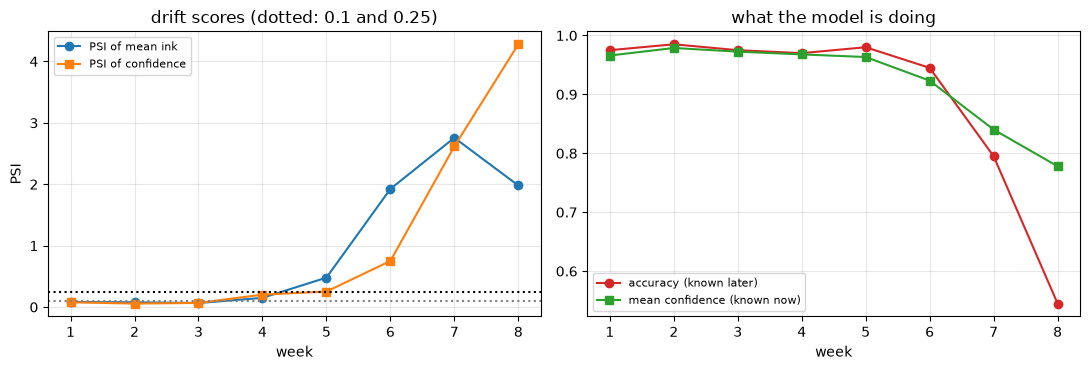


false alarms on 150 batches of 200 with NO drift: {'KS p<0.05 on ink': '3%', 'PSI ink > 0.1': '11%', 'PSI ink > 0.25': '0%', 'any of 64 pixels, KS p<0.05': '35%', 'any of 64 pixels, Bonferroni': '0%'}
time 6 s


In [12]:
t0 = time.time()
def psi(ref, cur, bins=10):
    edges = np.quantile(ref, np.linspace(0, 1, bins + 1)); edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-4, None); c = np.clip(np.histogram(cur, edges)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

# ---- schema checks ----
COLS = [f"p{i}" for i in range(64)]
def validate(df):
    problems = []
    missing = [c for c in COLS if c not in df.columns]; extra = [c for c in df.columns if c not in COLS]
    if missing: problems.append(f"missing columns {missing[:3]}")
    if extra: problems.append(f"unexpected columns {extra[:3]}")
    num = df[[c for c in COLS if c in df.columns]]
    if (nan := num.isna().mean().max()) > 0.01: problems.append(f"null rate {nan:.1%} above 1 %")
    if ((num < 0) | (num > 1)).mean().max() > 0.01: problems.append(f"values outside [0, 1] (max {np.nanmax(num.values):.1f})")
    return problems or ["ok"]
good = pd.DataFrame(X_test[:200], columns=COLS)
bad_null = good.copy(); bad_null.iloc[np.random.default_rng(0).random(good.shape) < 0.05] = np.nan
bad_unit = good * 16
bad_col = good.rename(columns={"p5": "pixel5"})
for name, df in [("clean batch", good), ("5 % nulls", bad_null), ("upstream unit change (0 to 16)", bad_unit), ("renamed column", bad_col)]:
    print(f"schema check, {name:32s}: {validate(df)}")

# ---- drift on a stream ----
net = mlp(0).fit(X_pool, y_pool)
feat = lambda X: X.mean(1)
conf = lambda X: net.predict_proba(X).max(1)
ref_f, ref_c = feat(X_pool), conf(X_pool)
rs = np.random.default_rng(11); fade = [1, 1, 1, 0.95, 0.9, 0.8, 0.7, 0.6]; jitter = [0, 0, 0, 0.02, 0.05, 0.1, 0.2, 0.3]
rows = []
for w, (g, sd) in enumerate(zip(fade, jitter), 1):
    ii = rs.choice(len(X_test), 200, replace=False); Xw = np.clip(X_test[ii] * g + rs.normal(0, sd, (200, 64)), 0, 1)
    ks_f = stats.ks_2samp(ref_f, feat(Xw)); ks_c = stats.ks_2samp(ref_c, conf(Xw))
    pix = sum(stats.ks_2samp(X_pool[:, j], Xw[:, j]).pvalue < 0.05 / 64 for j in range(64))
    rows.append((w, g, psi(ref_f, feat(Xw)), ks_f.pvalue, psi(ref_c, conf(Xw)), ks_c.pvalue, pix, float(conf(Xw).mean()), net.score(Xw, y_test[ii])))
df = pd.DataFrame(rows, columns=["week", "gain", "PSI ink", "KS p ink", "PSI conf", "KS p conf", "pixels flagged (Bonferroni)", "mean confidence", "accuracy"])
print(df.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(df.week, df["PSI ink"], "C0-o", label="PSI of mean ink"); ax[0].plot(df.week, df["PSI conf"], "C1-s", label="PSI of confidence")
ax[0].axhline(0.1, color="gray", ls=":"); ax[0].axhline(0.25, color="k", ls=":"); ax[0].set_xlabel("week"); ax[0].set_ylabel("PSI"); ax[0].legend(fontsize=8); ax[0].set_title("drift scores (dotted: 0.1 and 0.25)")
ax[1].plot(df.week, df.accuracy, "C3-o", label="accuracy (known later)"); ax[1].plot(df.week, df["mean confidence"], "C2-s", label="mean confidence (known now)")
ax[1].set_xlabel("week"); ax[1].legend(fontsize=8); ax[1].set_title("what the model is doing")
plt.tight_layout(); plt.show()

# ---- false alarms on batches with no drift ----
fa = {"KS p<0.05 on ink": 0, "PSI ink > 0.1": 0, "PSI ink > 0.25": 0, "any of 64 pixels, KS p<0.05": 0, "any of 64 pixels, Bonferroni": 0}
nb = 150
for _ in range(nb):
    Xw = X_test[rs.choice(len(X_test), 200, replace=False)]
    fa["KS p<0.05 on ink"] += stats.ks_2samp(ref_f, feat(Xw)).pvalue < 0.05
    p_ = psi(ref_f, feat(Xw)); fa["PSI ink > 0.1"] += p_ > 0.1; fa["PSI ink > 0.25"] += p_ > 0.25
    pv = np.array([stats.ks_2samp(X_pool[:, j], Xw[:, j]).pvalue for j in range(64)])
    fa["any of 64 pixels, KS p<0.05"] += (pv < 0.05).any(); fa["any of 64 pixels, Bonferroni"] += (pv < 0.05 / 64).any()
print(f"\nfalse alarms on {nb} batches of 200 with NO drift:", {k: f"{v / nb:.0%}" for k, v in fa.items()})
print(f"time {time.time() - t0:.0f} s")

**Reading.** The schema checks caught all four injected faults at once and with a readable message: the batch with nulls (the largest per-column null rate was 8.5 % against the 5 % injected, a sampling effect of 200 rows), the upstream unit change (values up to 16), and the renamed column (reported both as missing and as unexpected). On the drift stream, the first three weeks stay below the 0.1 PSI level (0.065 to 0.082). **The input alarm fires well before the accuracy moves**: in week 4 the PSI of mean ink is 0.149 (moderate), the KS test has p = 0.001 and 56 of the 64 pixels are flagged with the Bonferroni correction, while the accuracy is still 0.970; in week 5 the PSI is 0.479, above the 0.25 alarm level, with accuracy 0.980; the accuracy first falls in week 6 (0.945), then 0.795 in week 7 and 0.545 in week 8. The model's own **mean confidence** is a free signal of the damage: it falls from 0.963 to 0.923 in week 6, before the accuracy collapse, and tracks it afterwards (0.778 in week 8). PSI is not a damage gauge: the PSI of mean ink *decreases* from 2.76 to 1.98 in week 8 because the added noise raises the mean ink back towards the reference, even though the accuracy is far worse. The false-alarm measurements on 150 batches with no drift are the part usually skipped: the KS test on mean ink raised an alarm at its 5 % level 3 % of the time, **the common 0.1 PSI threshold fired in 11 % of clean batches** (with 200 examples and 10 bins, the PSI has a positive bias), the 0.25 threshold never, testing each of the 64 pixels at 5 % gave an alarm on 35 % of clean batches, and the Bonferroni-corrected version on 0 %. Calibrate alarm thresholds on your own no-drift batches at your own batch size. The drift here was applied to every image at once; real drift is often partial and can hurt with little visible shift in the monitored statistics, so keep the confidence and the delayed accuracy as well.

## 13. Documentation and versioning

A dataset that nobody can describe or reproduce cannot be debugged. Two habits fix most of it.

**Datasheets for datasets** (Gebru et al., 2021) is a questionnaire answered when a dataset is made, grouped by the life cycle: *motivation* (why was it created, by whom, funded by whom), *composition* (what are the instances, how many, is there missing data, are there groups of people and how are they represented, is there anything confidential), *collection process* (how was it acquired, who labelled it and how, over what time), *preprocessing and cleaning*, *uses* (intended and inappropriate), *distribution* (licence, access), and *maintenance* (who maintains it, how are errors reported). Its sibling for models is the **model card** (Mitchell et al., 2019). The questions that matter most for the topics of this notebook: who labelled and with what guidelines (section 5), what duplicates and group structure exist (section 6), what was cleaned or relabelled and how (section 3), and what monitoring thresholds were set (section 12).

**Versioning.** Data changes more often than code and breaks results more silently. Minimum viable practice: give every dataset version a **content hash** (so "the data we trained on" is a fact, not a memory), store the labelling guideline version and the cleaning steps beside it, and record the hash in the training run. Tools that do this at scale: [DVC](https://dvc.org) (data version control, git-style tracking of large files), the dataset versioning of the Hugging Face Hub, and lakehouse table formats with time travel. Below, a datasheet as a plain dictionary and hashes before and after the cleaning of section 3: the hash changes, the datasheet records why.

In [13]:
def data_hash(X, y):
    h = hashlib.sha256(); h.update(np.ascontiguousarray(X, dtype=np.float32).tobytes()); h.update(np.ascontiguousarray(y, dtype=np.int16).tobytes())
    return h.hexdigest()[:16]

yn_demo = flip_sym(ytr, 0.2, 400); keep = ~cl_flag(oof(lambda: mlp(0), Xtr, yn_demo, 0), yn_demo)
datasheet = {
    "name": "digits-1000-noisy (teaching subset)",
    "motivation": "teach label-noise handling; derived from the UCI optical digits test set (CC BY 4.0, doi:10.24432/C50P49)",
    "composition": {"instances": int(len(ytr)), "features": "64 pixel intensities scaled to [0, 1]", "classes": 10, "missing": "none"},
    "collection": "20 % symmetric label noise injected with seed 400; true labels kept separately for evaluation only",
    "known_issues": ["labels were corrupted on purpose", "no writer identifiers, so duplicates by writer cannot be ruled out"],
    "cleaning": {"method": "confident learning, 5-fold MLP, drop flagged", "examples_removed": int((~keep).sum())},
    "intended_use": "teaching and benchmarking of data-quality methods",
    "inappropriate_use": "any claim about real handwriting recognition",
    "monitoring": "PSI on mean ink, alarm above 0.25; KS with Bonferroni on pixels",
    "maintainer": "course authors; report errors through the course site",
}
datasheet["version_hash_raw"] = data_hash(Xtr, yn_demo)
datasheet["version_hash_cleaned"] = data_hash(Xtr[keep], yn_demo[keep])
print(json.dumps(datasheet, indent=2))
print("hash is stable across runs:", data_hash(Xtr, yn_demo) == datasheet["version_hash_raw"])

{
  "name": "digits-1000-noisy (teaching subset)",
  "motivation": "teach label-noise handling; derived from the UCI optical digits test set (CC BY 4.0, doi:10.24432/C50P49)",
  "composition": {
    "instances": 1000,
    "features": "64 pixel intensities scaled to [0, 1]",
    "classes": 10,
    "missing": "none"
  },
  "collection": "20 % symmetric label noise injected with seed 400; true labels kept separately for evaluation only",
  "known_issues": [
    "labels were corrupted on purpose",
    "no writer identifiers, so duplicates by writer cannot be ruled out"
  ],
  "cleaning": {
    "method": "confident learning, 5-fold MLP, drop flagged",
    "examples_removed": 172
  },
  "intended_use": "teaching and benchmarking of data-quality methods",
  "inappropriate_use": "any claim about real handwriting recognition",
  "monitoring": "PSI on mean ink, alarm above 0.25; KS with Bonferroni on pixels",
  "maintainer": "course authors; report errors through the course site",
  "version_has

## 14. A checklist for data-centric work

1. **Look at the data first.** Sample 50 examples per class and read them; compute class counts and duplicate counts before any modelling.
2. **Fix the evaluation before the model.** A clean, representative, **group-split** test set that never changes comes first (section 6); its labels deserve the most scrutiny, because every later decision is judged on it.
3. **Measure label quality**, do not assume it: have a subset labelled twice and compute kappa (section 5); look at the confusions, not only the total.
4. **Run a noise detector** (section 3) and read the top flagged examples *by hand* before dropping or relabelling anything; check on a held-out set that cleaning helped, and check at zero noise that it did not hurt (section 4).
5. **Draw the learning curve with a band** (section 7) before buying labels; if the curve is flat, change the model or the data *kind*, not the amount.
6. **If labels are the bottleneck**: active learning with a hybrid strategy (section 9), weak supervision for the bulk (section 11), and still a small gold set to evaluate both.
7. **Augment with domain knowledge**, test the augmentations one at a time; treat synthetic data as a supplement for coverage, never as a substitute for fresh real data (section 10).
8. **Validate every batch** and **monitor drift** of inputs and outputs, with thresholds set from no-drift false-alarm rates, not from a rule of thumb alone (section 12).
9. **Document and version** the data: datasheet, guideline version, content hash recorded with every training run (section 13).
10. **Decide with numbers**: when the model-centric and data-centric levers both exist, run the small contest of section 4 on your own task, with seeds.

## Key takeaways

* The data-centric thesis was **tested, not assumed**: with label noise, cleaning the data with a fixed model was compared to a bigger, tuned or different model (section 4). At 20 and 40 % label noise, ensemble-vote cleaning lifted accuracy from 0.911 and 0.824 to 0.961 and 0.947, a bigger network lowered it to 0.843 and 0.655, and swapping to a random forest (0.959 and 0.927) captured most of the gain without any data work; with clean labels cleaning slightly hurt (0.977 fell to 0.975 and 0.968). Verdict: true for noisy labels, not supported for clean ones, and not exclusive of a model change.
* **Label noise** costs accuracy in a way that depends on its structure: class-dependent mistakes were more damaging than random ones at the same rate, and noisy test labels also corrupt the *measurement* (section 2).
* **Detecting wrong labels** works without any extra labels, from out-of-sample predictions; confident learning, a loss rule and ensemble disagreement were compared with known truth (section 3). Detection quality and the downstream gain are different things.
* **Annotation quality** is measurable (kappa), is concentrated in look-alike classes, and guideline changes can be tested (section 5).
* **Leakage** inflates the test score without any bug in the model; group splits and duplicate detection remove the inflation, and a leaking feature is invisible until deployment (section 6).
* **Learning curves with bands** tell whether more data of the same kind can help; power-law extrapolation is useful only if it passes a held-out check (section 7).
* **Data valuation** ranks points by contribution; Shapley estimation is noisier and costlier than leave-one-out and we measured both (section 8).
* **Active learning** can save labels but the gains depend on the strategy, the stage of the budget and the seed (section 9).
* **Augmentation** helps only when it preserves the label; **synthetic data** cannot add what the generator never saw; **recursive training on generated data** narrows the distribution and loses rare modes unless real data keeps entering (section 10).
* **Weak supervision** trades label quality for volume and relies on an independence assumption that we saw break (section 11).
* **Monitor** with schema checks and drift statistics, and calibrate alarms on no-drift batches (section 12).
* **Document and version** data like code (section 13).

## Exercises

1. In section 2, add a third noise type: **asymmetric rare-class noise** where only class 9 is corrupted (to class 4) with probability $\rho$. How does the overall accuracy compare with the same total noise spread evenly, and what does per-class recall show?
2. In section 3, change the cross-validation to 2 folds and to 10 folds. How do precision, recall and the downstream accuracy move? Replace the MLP by the random forest as the detector's model.
3. In section 4, add a **label-smoothing** or **early-stopping** arm (a model-centric defence against noise). Does it close the gap to cleaning at 40 % noise?
4. In section 5, give the three annotators **correlated** mistakes (they all confuse the same pairs in the same direction) and compare the majority vote with the independent case.
5. In section 6, change the duplicate noise level from 0.08 to 0.3. At what level does the distance threshold stop separating copies from different images, and what happens to the discovered groups?
6. In section 7, draw learning curves for the random forest and for the MLP with a larger L2 penalty. For which model is the extrapolation to 1000 best? What would you do with a curve whose test error is flat from $n = 250$?
7. In section 8, change the utility to log-loss on the validation set instead of accuracy. Is the ranking of flipped points more reliable? How does the agreement between independent halves of the permutations change with 60 permutations in total and with 960?
8. In section 9, add **expected error reduction by cheap proxy**: query-by-committee with 5 bootstrap logistic regressions. Does it beat the hybrid strategy at 100 labels, with 10 seeds?
9. In section 10, run the collapse toy with $N = 200$ instead of 60. How does the generation at which the rare bump disappears depend on $N$? Which sample size makes `replace` safe for 25 generations?
10. In section 11, add one deliberately **bad** labelling function (accuracy 50 %) and see how well the label model down-weights it compared with the majority vote.
11. In section 12, add a **stuck sensor** (a pixel fixed to 0) in week 6 and compare which statistic notices it first: PSI on mean ink, the Bonferroni KS on pixels, or accuracy.
12. Take a dataset from your own work, write its datasheet (section 13) and answer honestly the question "who labelled this and how do we know they agreed?".

## References

* Ng, A. (2021). A chat with Andrew on MLOps: from model-centric to data-centric AI (talk, DeepLearning.AI): https://www.youtube.com/watch?v=06-AZXmwHjo . Course: Introduction to Data-Centric AI, MIT (IAP 2024): https://dcai.csail.mit.edu/
* Northcutt, C. G., Jiang, L. and Chuang, I. L. (2021). Confident learning: estimating uncertainty in dataset labels. *Journal of Artificial Intelligence Research* 70. arXiv:1911.00068: https://arxiv.org/abs/1911.00068
* Northcutt, C. G., Athalye, A. and Mueller, J. (2021). Pervasive label errors in test sets destabilize machine learning benchmarks. NeurIPS Datasets and Benchmarks. arXiv:2103.14749: https://arxiv.org/abs/2103.14749
* cleanlab, open-source library for finding label issues: https://github.com/cleanlab/cleanlab
* Settles, B. (2009). Active learning literature survey. Computer Sciences Technical Report 1648, University of Wisconsin-Madison: https://minds.wisconsin.edu/handle/1793/60660
* Ratner, A., Bach, S. H., Ehrenberg, H., Fries, J., Wu, S. and Re, C. (2017). Snorkel: rapid training data creation with weak supervision. *VLDB* 11(3). arXiv:1711.10160: https://arxiv.org/abs/1711.10160
* Ghorbani, A. and Zou, J. (2019). Data Shapley: equitable valuation of data for machine learning. ICML. arXiv:1904.02868: https://arxiv.org/abs/1904.02868
* Shumailov, I., Shumaylov, Z., Zhao, Y., Gal, Y., Papernot, N. and Anderson, R. (2023). The curse of recursion: training on generated data makes models forget. arXiv:2305.17493: https://arxiv.org/abs/2305.17493
* Shumailov, I., Shumaylov, Z., Zhao, Y., Papernot, N., Anderson, R. and Gal, Y. (2024). AI models collapse when trained on recursively generated data. *Nature* 631, 755-759: https://doi.org/10.1038/s41586-024-07566-y
* Gerstgrasser, M. et al. (2024). Is model collapse inevitable? Breaking the curse of recursion by accumulating real and synthetic data. arXiv:2404.01413: https://arxiv.org/abs/2404.01413
* Sambasivan, N., Kapania, S., Highfill, H., Akrong, D., Paritosh, P. and Aroyo, L. (2021). "Everyone wants to do the model work, not the data work": data cascades in high-stakes AI. CHI. https://doi.org/10.1145/3411764.3445518
* Gebru, T. et al. (2021). Datasheets for datasets. *Communications of the ACM* 64(12). arXiv:1803.09010: https://arxiv.org/abs/1803.09010
* Mitchell, M. et al. (2019). Model cards for model reporting. FAT*. arXiv:1810.03993: https://arxiv.org/abs/1810.03993
* Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement* 20(1), 37-46: https://doi.org/10.1177/001316446002000104
* Alpaydin, E. and Kaynak, C. (1998). Optical Recognition of Handwritten Digits (UCI Machine Learning Repository, CC BY 4.0): https://doi.org/10.24432/C50P49
* Great Expectations (data validation): https://greatexpectations.io . DVC (data version control): https://dvc.org

In [14]:
print(f"total notebook run time: {time.time() - T_START:.0f} s")

total notebook run time: 158 s
